In [ ]:
%load_ext autoreload
%autoreload 2

### Figure 2: Dataset collection and benchmarking.

 - __a)__ Collected datasets table.
 - __b)__ Dataset statistics.
 - __d)__ MS benchmarking.
 - __e)__ Non-MS benchmarking.

__Note:__ The individual test and train sets already contain the score columns for the benchmarked models.

In [ ]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT.name != "PepCL_Manuscript":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Could not find PepCL_Manuscript project root.")
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "Data"
SRC_DIR = PROJECT_ROOT / "src"
FIGURES_DIR = PROJECT_ROOT / "Figures"
MODEL_CHECKPOINTS_DIR = PROJECT_ROOT / "Model_Checkpoints"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("PROJECT_ROOT in sys.path:", str(PROJECT_ROOT) in sys.path)

PROJECT_ROOT: /home/pchati/PepCL_Manuscript
PROJECT_ROOT in sys.path: True


In [ ]:
# get mhc pseudosequences (process before you use)
from Data.mhc_pseudo_seqs import mhc_seq_dict
mhc_seq_dict={k.removeprefix("HLA-").replace("*","").replace(":",""):v for k,v in mhc_seq_dict.items()}

# imports
from src.general_utils import *
from src.get_feature_data import *
from src.plotting import *
from src.louvain_clustering import *
from src.resampled_jsd import *

# misc
import warnings
warnings.filterwarnings("ignore")
device="cuda"

In [ ]:
"""
Set figure output directory
"""
# create central repository and for this figure
central_figure_dir="Figure2"

# associated data dir
associated_data_dir=f"{central_figure_dir}/Associated_Data"

### Fig. 2a: Collected datasets table

In [ ]:
%%time
# get the major collected dfs

# ms train and test sets
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_train_data=pd.read_csv(f"{datasets_dir}/ms_train_data.csv", index_col=0)
ms_test_data=pd.read_csv(f"{datasets_dir}/ms_test_data.csv", index_col=0)
ms_dataset=pd.concat([ms_train_data, ms_test_data])
ms_dataset_pos=ms_dataset.query("label == 1") # get positives only since negatives are synthetic

# yd train and test sets
holec_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "Holec_et_al_2025"
holec_train_set = pd.read_csv(f"{holec_datasets_dir}/holec_train_set.csv", index_col=0)
holec_test_set  = pd.read_csv(f"{holec_datasets_dir}/holec_test_set.csv", index_col=0)
holec_dataset=pd.concat([holec_train_set, holec_test_set])

# episcan train and test sets
episcan_train_test_dir = DATA_DIR / "Training_Datasets" / "Processed" / "EpiScan"
episcan_r9_train_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_train_set.csv", index_col=0)
episcan_r9_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_test_set.csv", index_col=0)
episcan_r9_dataset=pd.concat([episcan_r9_train_set, episcan_r9_test_set])

episcan_rt_train_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_train_set.csv", index_col=0)
episcan_rt_test_set=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_test_set.csv", index_col=0)
episcan_rt_dataset=pd.concat([episcan_rt_train_set, episcan_rt_test_set])

sd3_formatted=pd.read_csv(f"{episcan_train_test_dir}/sd3_formatted.csv", index_col=0)

# ba dataset
nmp_ba_data_hla=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/BA/nmp_ba_data_hla.csv", index_col=0)

# escape seq datasets
escape_seq_datasets_dir = DATA_DIR / "Training_Datasets/Processed/ESCAPE_seq"
oncogene_mut_wt_df=pd.read_csv(f"{escape_seq_datasets_dir}/oncogene_mut_wt_df.csv", index_col=0)
iedb_escapeseq_df_processed=pd.read_csv(f"{escape_seq_datasets_dir}/iedb_escapeseq_df_processed.csv", index_col=0)
sars_escapeseq_df_processed=pd.read_csv(f"{escape_seq_datasets_dir}/sars_escapeseq_df_processed.csv", index_col=0)

CPU times: user 53.1 s, sys: 17.8 s, total: 1min 10s
Wall time: 1min 10s


In [ ]:
%%time
# process all
ms_dataset=full_process_data(ms_dataset, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_dataset=create_seq_allele_column(ms_dataset)

ms_dataset_pos=full_process_data(ms_dataset_pos, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_dataset_pos=create_seq_allele_column(ms_dataset_pos)

holec_dataset=full_process_data(holec_dataset, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
holec_dataset=create_seq_allele_column(holec_dataset)

episcan_r9_dataset=full_process_data(episcan_r9_dataset, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_r9_dataset=create_seq_allele_column(episcan_r9_dataset)

episcan_rt_dataset=full_process_data(episcan_rt_dataset, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_rt_dataset=create_seq_allele_column(episcan_rt_dataset)

sd3_formatted=full_process_data(sd3_formatted, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
sd3_formatted=create_seq_allele_column(sd3_formatted)

nmp_ba_data_hla=full_process_data(nmp_ba_data_hla, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
nmp_ba_data_hla=create_seq_allele_column(nmp_ba_data_hla)

oncogene_mut_wt_df=full_process_data(oncogene_mut_wt_df, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
oncogene_mut_wt_df=create_seq_allele_column(oncogene_mut_wt_df)

iedb_escapeseq_df_processed=full_process_data(iedb_escapeseq_df_processed, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
iedb_escapeseq_df_processed=create_seq_allele_column(iedb_escapeseq_df_processed)

sars_escapeseq_df_processed=full_process_data(sars_escapeseq_df_processed, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
sars_escapeseq_df_processed=create_seq_allele_column(sars_escapeseq_df_processed)

CPU times: user 1min 7s, sys: 51.7 s, total: 1min 59s
Wall time: 1min 59s


In [ ]:
# get merged full sets
episcan_dataset=pd.concat([episcan_r9_dataset, episcan_rt_dataset, sd3_formatted])
escape_seq_dataset=pd.concat([oncogene_mut_wt_df, iedb_escapeseq_df_processed, sars_escapeseq_df_processed])

In [ ]:
# map holec virus set
virus_map = {
    'cov': ['CoV-BA.1', 'CoV-BA.2', 'CoV-alpha', 'CoV-beta', 'CoV-delta', 'CoV-gamma', 'CoV'],
    'denv': ['DENV_1', 'DENV_2C', 'DENV_2', 'DENV_3', 'DENV_4'],
    'mtb': ['Mtb-T7SS', 'Mtb-Vac2', 'Mtb-Vac'],
    'zika': ['Zika'],
}

def map_virus_type(df, virus_dict, subtype_col, new_col):
    reverse = {sub: virus for virus, subs in virus_dict.items() for sub in subs}
    df = df.copy()
    df[new_col] = df[subtype_col].map(reverse)
    return df

holec_dataset=map_virus_type(holec_dataset, virus_map, "protein_set", "virus")

In [ ]:
# dataset summary table

# tuple in holec is for splitting based on virus
dict_of_dfs={
    "ms": ms_dataset_pos,

    "holec_main": holec_dataset, # total
    "holec": (holec_dataset, "virus"),

    "episcan": episcan_dataset, # total
    "episcan_r9": episcan_r9_dataset, 
    "episcan_rt": episcan_rt_dataset, 
    "episcan_cov": sd3_formatted, 

    "ba": nmp_ba_data_hla,

    "escape": escape_seq_dataset, # total
    "escape_paired": oncogene_mut_wt_df,
    "escape_iedb": iedb_escapeseq_df_processed,
    "escape_cov": sars_escapeseq_df_processed,

}

summary_df=summarize_datasets_wide(dict_of_dfs, label_col='label', seq_col='seq', allele_col='allele')

# filter down to certain columns and use seq allele specifically
summary_df_filtered=summary_df[["dataset", "pos_unique_seq_allele", "neg_unique_seq_allele", "total_unique_alleles"]]
summary_df_filtered.columns=["Dataset", "Binders", "Non-binders", "Alleles"]

In [ ]:
# filter down to certain columns and use seq allele specifically
summary_df_filtered=summary_df[["dataset", "pos_unique_seq_allele", "neg_unique_seq_allele", "total_unique_alleles"]]
summary_df_filtered.columns=["Dataset", "Binders", "Non-binders", "Alleles"]

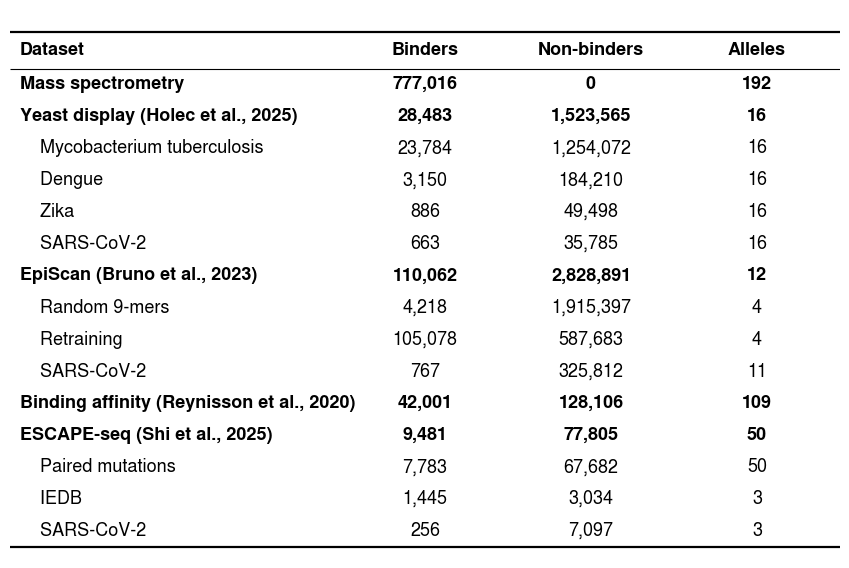

In [ ]:
# need a dict of each dataset name to tuple, where first item indicates subgroup or group and second indicates the items name in the table

# create default dict then edit
table_formatting_dict={k: ("subgroup", "name") for k in summary_df_filtered.Dataset.tolist()}

table_formatting_dict={
    'ms': ('group', 'Mass spectrometry'),
    'holec_main': ('group', 'Yeast display (Holec et al., 2025)'),
    'holec_mtb': ('subgroup', 'Mycobacterium tuberculosis'),
    'holec_denv': ('subgroup', 'Dengue'),
    'holec_zika': ('subgroup', 'Zika'),
    'holec_cov': ('subgroup', 'SARS-CoV-2'),
    'episcan': ('group', 'EpiScan (Bruno et al., 2023)'),
    'episcan_r9': ('subgroup', 'Random 9-mers'),
    'episcan_rt': ('subgroup', 'Retraining'),
    'episcan_cov': ('subgroup', 'SARS-CoV-2'),
    'ba': ('group', 'Binding affinity (Reynisson et al., 2020)'),
    'escape': ('group', 'ESCAPE-seq (Shi et al., 2025)'),
    'escape_paired': ('subgroup', 'Paired mutations'),
    'escape_iedb': ('subgroup', 'IEDB'),
    'escape_cov': ('subgroup', 'SARS-CoV-2')
}

plot_publication_dataset_table(
    df=summary_df_filtered,
    dataset_meta=table_formatting_dict,
    col_widths=[0.40, 0.20, 0.20, 0.20],
    title = "",
    save_path = None,
    # save_path=f"{central_figure_dir}/fig2_a_dataset_seq_allele_group_and_subgroup_counts_table",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    summary_df.to_csv(f"{associated_data_dir}/dataset_statistics_summary_df.csv")

### Fig. 2b: Dataset statistics

In [ ]:
# get binders only
dict_of_dfs={
    "ms": ms_dataset_pos,

    "holec_main": holec_dataset.query("label == 1"), # total

    "episcan": episcan_dataset.query("label == 1"), # total
    "episcan_r9": episcan_r9_dataset.query("label == 1"), 
    "episcan_rt": episcan_rt_dataset.query("label == 1"), 
    "episcan_cov": sd3_formatted.query("label == 1"), 

    "ba": nmp_ba_data_hla.query("label == 1"),

    "escape": escape_seq_dataset.query("label == 1"), # total
    "escape_paired": oncogene_mut_wt_df.query("label == 1"),
    "escape_iedb": iedb_escapeseq_df_processed.query("label == 1"),
    "escape_cov": sars_escapeseq_df_processed.query("label == 1"),
}

for df_name, df in tqdm(dict_of_dfs.items()):
    df["peptide"]=df.seq.str.replace("$", "")
    dict_of_dfs[df_name]=df

100%|██████████| 11/11 [00:00<00:00, 28.64it/s]


In [ ]:
%%time
# compute jsd
# js_by_allele_len, js_by_allele_unweighted, js_by_allele_weighted=compute_js_divergence_pwms_gpu(
#     ref_df=ms_dataset_pos, 
#     test_dfs=dict_of_dfs, # already filtered for pos only
#     allele_col = "allele",
#     seq_col = "peptide",
#     peptide_lengths=None,
#     aa_alphabet = AA_ALPHABET_20,
#     pseudocount = 1.0,
#     device = "cuda",
#     drop_invalid_peptides = True,
#     min_peptides_per_group = 10,
#     normalize_js_by_length = True,
# )

js_len_df_resamp, js_allele_unw_resamp, js_allele_w_resamp = compute_js_divergence_pwms_gpu_resampled(
    dfs=dict_of_dfs,
    ref_df_key="ms",
    allele_col="allele",
    seq_col="peptide",
    peptide_lengths=None,
    pseudocount=1.0,
    device="cuda",
    drop_invalid_peptides=True,
    min_peptides_per_group=10,
    normalize_js_by_length=True,
    iterations=10,
    subsample_size_or_frac=0.05,
    random_state=42,
)


JS vs full ref: escape_cov: 100%|██████████| 889/889 [00:00<00:00, 334475.80it/s]


CPU times: user 9.18 s, sys: 921 ms, total: 10.1 s
Wall time: 10.1 s


In [ ]:
# compute p-values
ref_col="ms"
cols=["holec_main", "episcan", "episcan_r9", "episcan_rt", "episcan_cov", "ba", "escape", "escape_paired", "escape_iedb", "escape_cov"]
paired_pvals_resamp=paired_wilcoxon_vs_ref(
    js_len_df_resamp,
    ref_col,
    cols,
    alternative="two-sided",
    zero_method="wilcox",
    correction=False,
    drop_nonfinite=True,
)

paired_pvals_resamp=add_star_col(paired_pvals_resamp, "wilcoxon_pvalue", "wilcoxon_pvalue_star")
paired_pvals_resamp

,dataset,ref_col,n_matched_groups,n_ref_has_test_missing,n_test_has_ref_missing,wilcoxon_stat,wilcoxon_pvalue,median_ref,median_test,median_test_minus_ref,mean_test_minus_ref,wilcoxon_pvalue_star
0,holec_main,ms,16,416,0,0.0,3.051758e-05,0.012762,0.073542,0.054149,0.058231,****
1,episcan,ms,24,408,0,0.0,1.192093e-07,0.009608,0.099790,0.084193,0.084752,****
2,episcan_r9,ms,4,428,0,0.0,1.250000e-01,0.005471,0.069747,0.066331,0.069469,ns
3,episcan_rt,ms,4,428,0,0.0,1.250000e-01,0.005471,0.036975,0.032162,0.029856,ns
4,episcan_cov,ms,23,409,0,0.0,2.384186e-07,0.009941,0.106569,0.090000,0.094594,****
5,ba,ms,123,309,8,175.0,4.215692e-20,0.018820,0.068206,0.045322,0.069419,****
6,escape,ms,48,384,0,0.0,7.105427e-15,0.013492,0.110436,0.089862,0.101226,****
7,escape_paired,ms,45,387,0,0.0,5.684342e-14,0.013562,0.112749,0.092017,0.108421,****
8,escape_iedb,ms,6,426,0,0.0,3.125000e-02,0.006909,0.046285,0.039953,0.049603,*
9,escape_cov,ms,3,429,0,0.0,2.500000e-01,0.003746,0.070293,0.065576,0.077388,ns


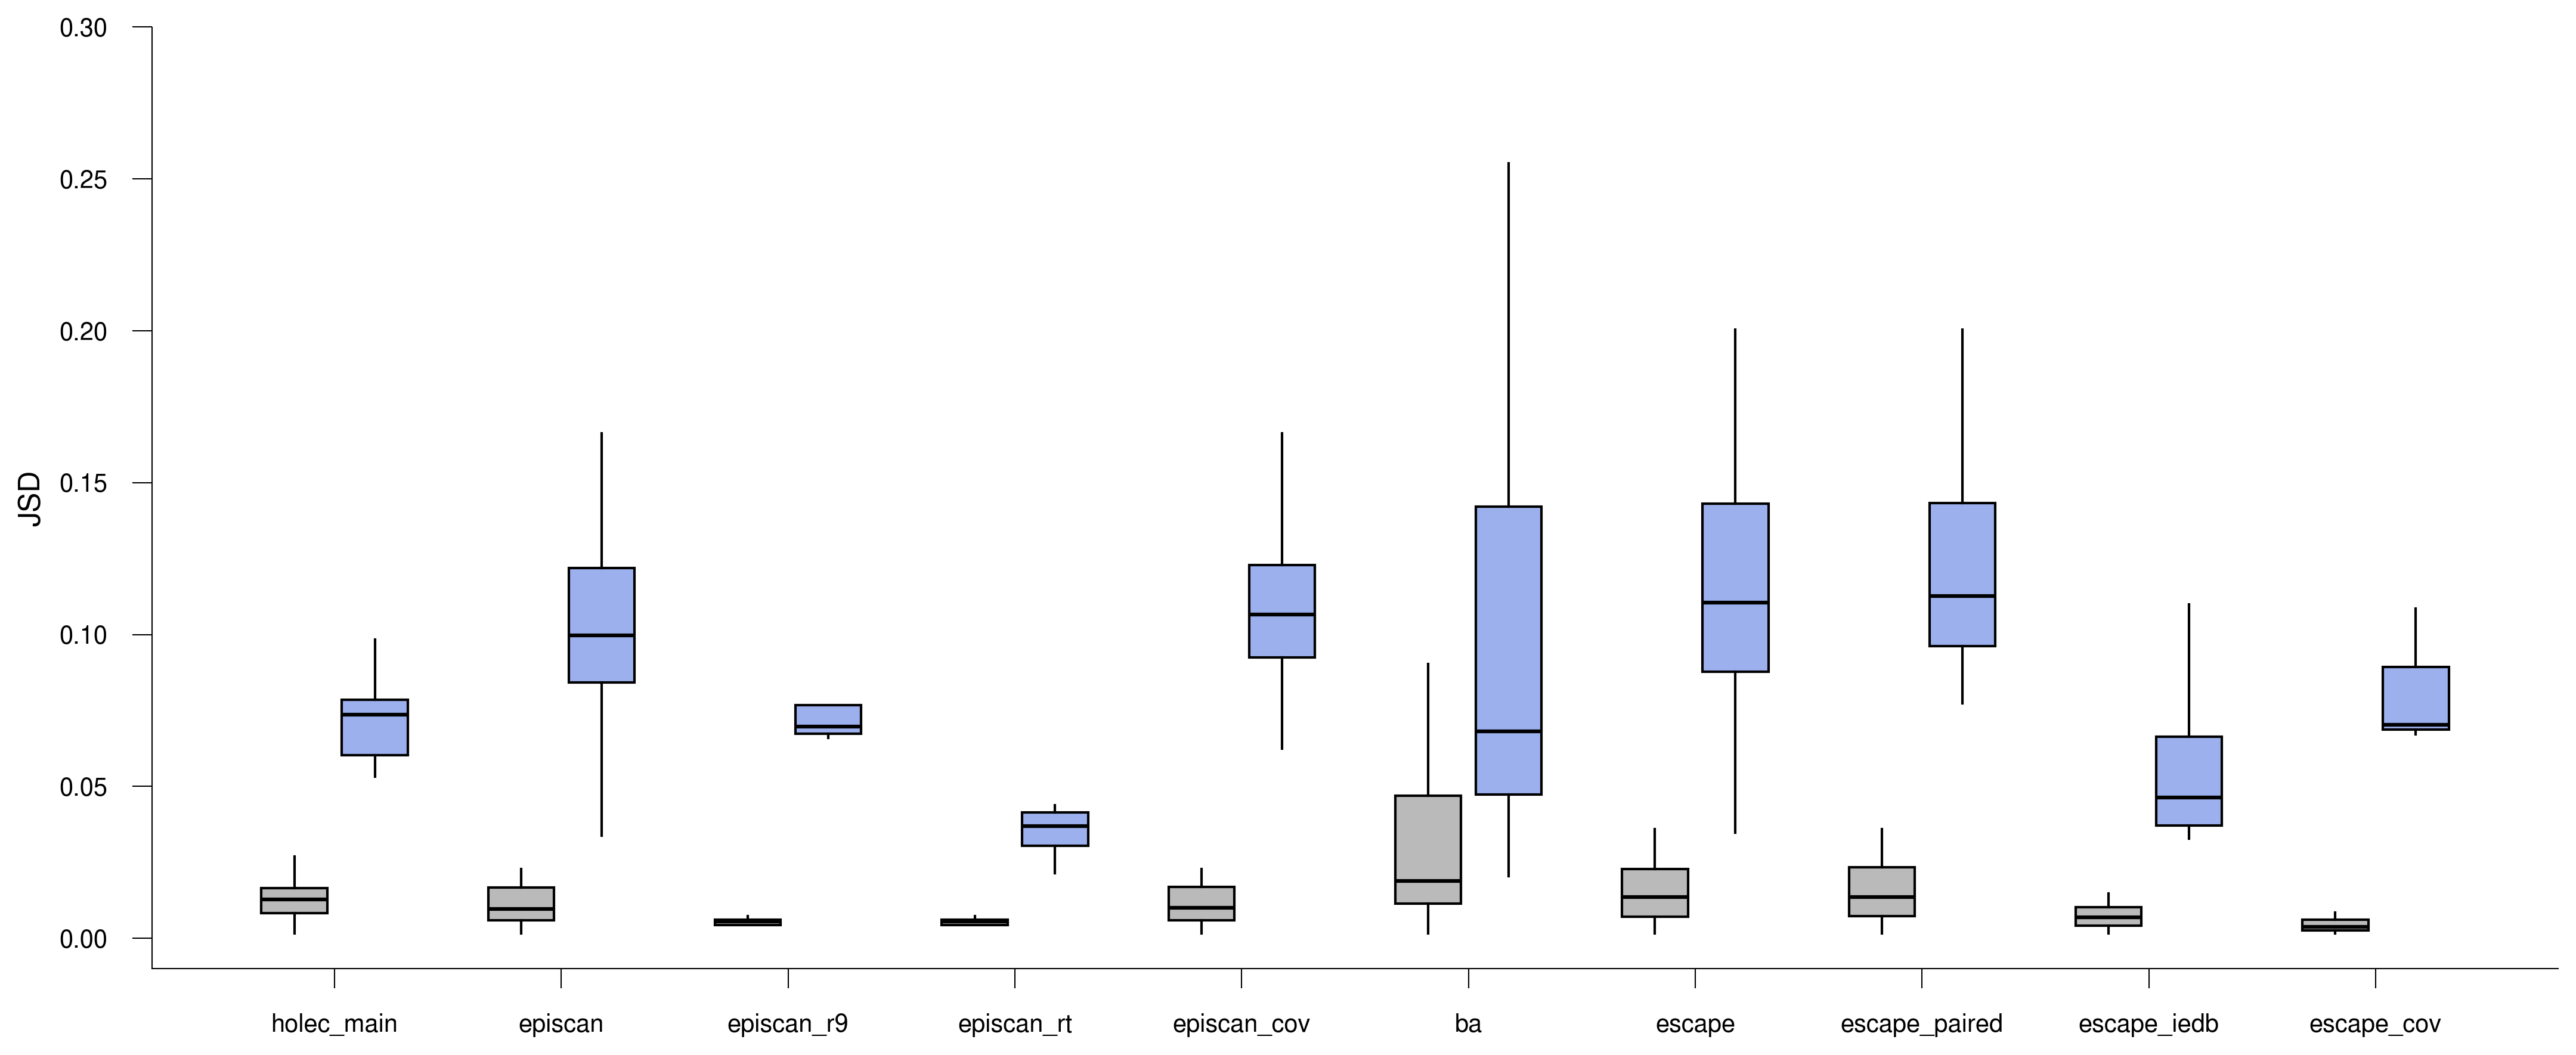

In [ ]:
# plot grouped boxplot
target_cluster_color="#9BB0ED"
prior_color="#bababa"
colors=["#bababa", "#9BB0ED"]
plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'JSD',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (14.5, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10

}

ref_col="ms"
cols=["holec_main", "episcan", "episcan_r9", "episcan_rt", "episcan_cov", "ba", "escape", "escape_paired", "escape_iedb", "escape_cov"]

_=paired_boxplot_vs_ref_styled(
    js_len_df_resamp,
    ref_col,
    cols,
    colors=colors,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.5,
    group_spacing=0.5,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=0,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style='--',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    legend_mode=None,
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    ylim=(-0.01, 0.3),
    save_path=None,
    # save_path=f"{central_figure_dir}/fig2_b_ms_ref_vs_dataset_granular_jsd_boxplots_matched_allele_lengths",

)

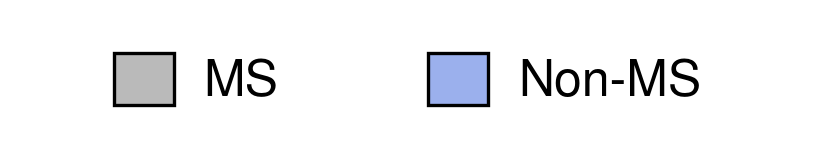

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'MS': '#bababa',
        'Non-MS': '#9bb0ed',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig2_b_top_jsd_legend",
)

In [ ]:
%%time
# map binders from each major dataset to human proteome

# human proteome
canonical_human_proteins=pd.read_csv(f"{DATA_DIR}/canonical_human_proteins.csv", index_col=0)

# pos only
dict_of_dfs_pos={
    "ms": ms_dataset_pos,
    "holec_main": holec_dataset.query("label == 1"),
    "episcan": episcan_dataset.query("label == 1"),
    "ba": nmp_ba_data_hla.query("label == 1"),
    "escape": escape_seq_dataset.query("label == 1"),
}

# add peptide col
for df_name, df in tqdm(dict_of_dfs_pos.items()):
    df["peptide"]=df.seq.str.replace("$", "")
    dict_of_dfs_pos[df_name]=df

pos_mapping_pct={}
for df_name, df in dict_of_dfs_pos.items():

    df_chp_mapping = map_peptides_to_proteins(df.seq.str.replace("$", "").unique().tolist(), canonical_human_proteins)
    mp_counts={k:len(v) for k,v in df_chp_mapping.items()}
    mapping_pct=compute_nonzero_percentage(mp_counts)
    pos_mapping_pct[df_name]=mapping_pct

# convert to df
pos_mapping_pct_df=pd.DataFrame.from_dict(pos_mapping_pct, orient="index")
pos_mapping_pct_df.reset_index(inplace=True)
pos_mapping_pct_df.columns=["dataset", "mp"]

100%|██████████| 5/5 [00:00<00:00, 13.23it/s]


Building Aho-Corasick automaton...


Adding peptides to automaton: 100%|██████████| 495621/495621 [00:00<00:00, 739751.97it/s]


Finalizing automaton...
Searching for peptides in proteins...


Processing proteins: 100%|██████████| 20338/20338 [00:06<00:00, 3027.78it/s]


...

Building Aho-Corasick automaton...


Adding peptides to automaton: 100%|██████████| 2705/2705 [00:00<00:00, 1442175.20it/s]


Finalizing automaton...
Searching for peptides in proteins...


Processing proteins: 100%|██████████| 20338/20338 [00:00<00:00, 23241.09it/s]

CPU times: user 15.4 s, sys: 772 ms, total: 16.2 s
Wall time: 16.1 s


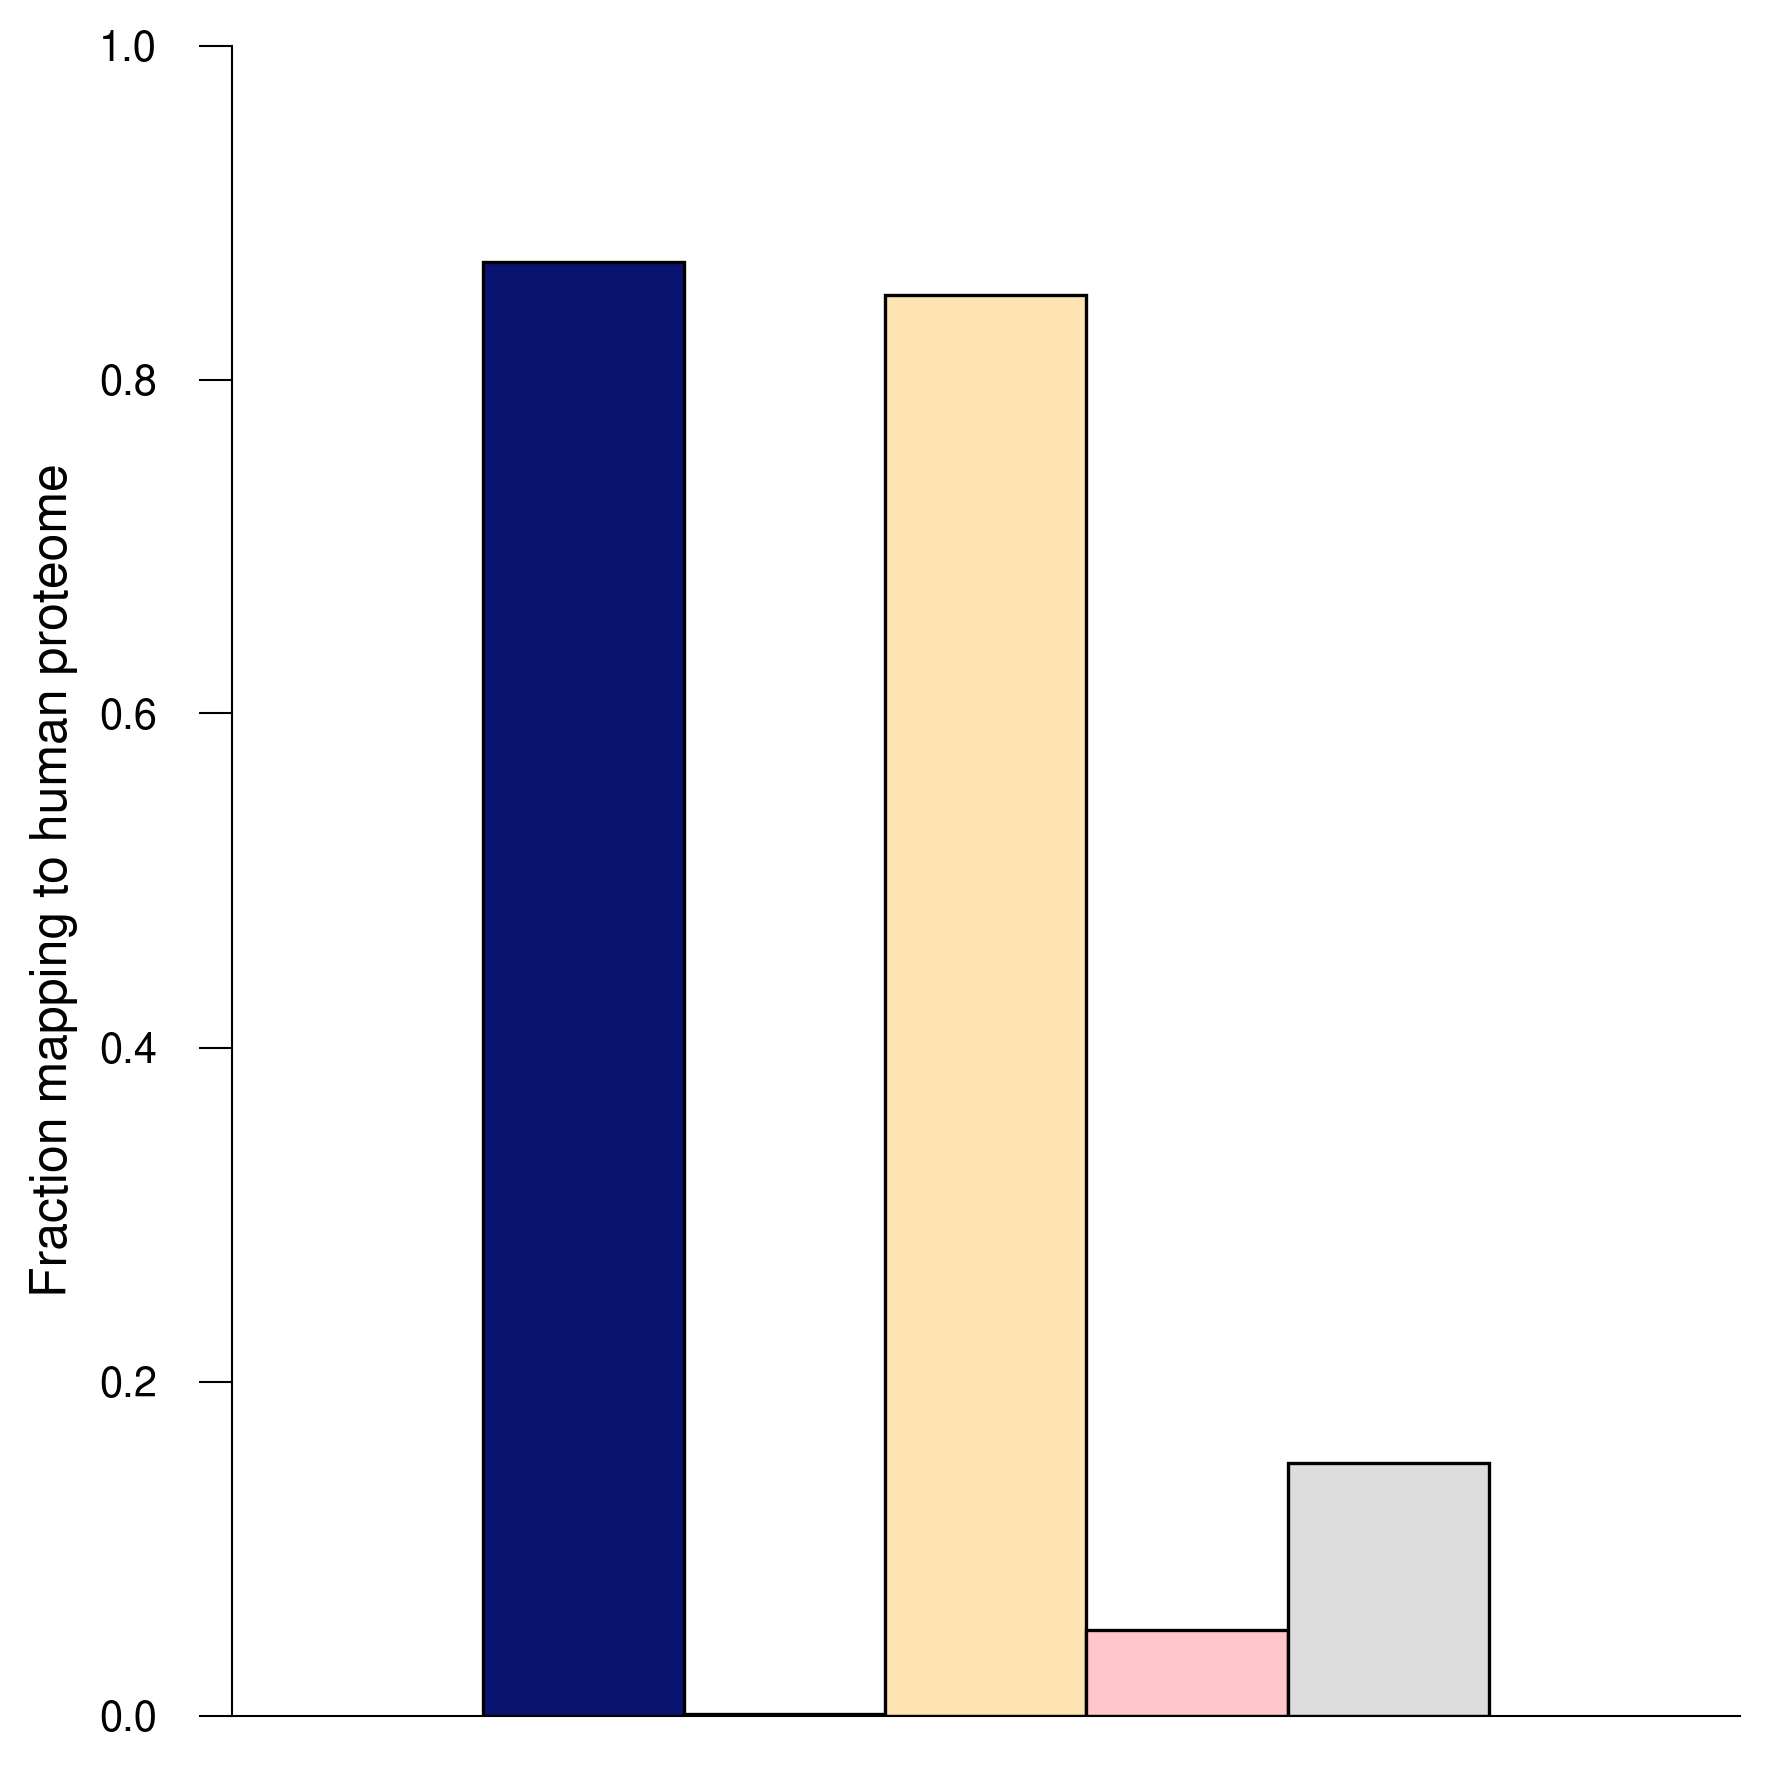

In [ ]:
# binder mapping to human proteome barplots

model_groups = {
    "ms": ["ms"],
    "holec_main": ["holec_main"],
    "episcan": ["episcan"],
    "ba": ["ba"],
    "escape": ["escape"],
}

x_ticks = ["datasets"]
colors = {
    "ms": "#081470",
    "holec_main": "#cad8f9",
    "episcan": "#ffe4b3",
    "ba": "#ffc7cc",
    "escape": "#dddddd",
}


plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Fraction mapping to human proteome',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (6, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10

}

_=plot_model_performance_bars_or_box_v2(
    df=pos_mapping_pct_df, 
    model_col='dataset',
    score_col='mp',
    model_groups=model_groups,
    x_ticks=None,
    colors=colors,
    plot_params=plot_params,
    ylim=(0.0, 1.0),
    grid_alpha=0,
    default_font='Nimbus Sans',
    bar_width=2.0,
    group_spacing=0.5,
    bar_spacing=0.0,
    bar_outline_color='black',
    bar_outline_width=0.8,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style=':',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=12,
    hline_text_offset=0.005,
    hline_text_x_offset=-0.035,
    hline_in_legend=True,
    legend_mode=None,
    mode='bar',
    box_flier_size=2,
    xtick_rotation=0,
    x_margin=2.5,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig2_b_dataset_binders_human_proteome_mapping_barplot"
)




In [ ]:
%%time
# corrected version relative to base
dict_of_dfs_all={
    "ms": ms_dataset,
    "holec_main": holec_dataset,
    "episcan": episcan_dataset,
    "ba": nmp_ba_data_hla,
    "escape": escape_seq_dataset,
}

# add peptide col
for df_name, df in tqdm(dict_of_dfs_all.items()):
    df["peptide"]=df.seq.str.replace("$", "")
    dict_of_dfs_all[df_name]=df

adjusted_cys_enrich_l2fc_df = compute_corrected_cysteine_l2fc_vs_ms(
    df_dict=dict_of_dfs_all,
    ms_key="ms",
    peptide_col="peptide",
    allele_col="allele",
    label_col="label",
    smoothing=True,
    pseudocount_num=0.5,
    pseudocount_den=1.0,
    deduplicate=True,
)

# summarize outputs
per_dataset_dict_adjusted_cys_enrich_l2fc, summary_df_adjusted_cys_enrich_l2fc=summarize_cysteine_l2fc_output(
    cys_l2fc_df=adjusted_cys_enrich_l2fc_df,
    dataset_col = "dataset",
    allele_col = "allele",
    l2fc_col = "cys_l2fc_ext_vs_ms",
)

100%|██████████| 5/5 [00:08<00:00,  1.77s/it]


CPU times: user 54.1 s, sys: 8.8 s, total: 1min 2s
Wall time: 1min 2s


In [ ]:
# rename the cols in each df and then print the matched allele counts for the n values in the figure annotations/caption
for df_name, df in per_dataset_dict_adjusted_cys_enrich_l2fc.items():
    print(df_name, len(df))
    df.rename(columns={"cys_l2fc_ext_vs_ms": f"cys_l2fc_ext_vs_ms_{df_name}"}, inplace=True)
    per_dataset_dict_adjusted_cys_enrich_l2fc[df_name]=df

holec_main 16
episcan 12
ba 83
escape 45


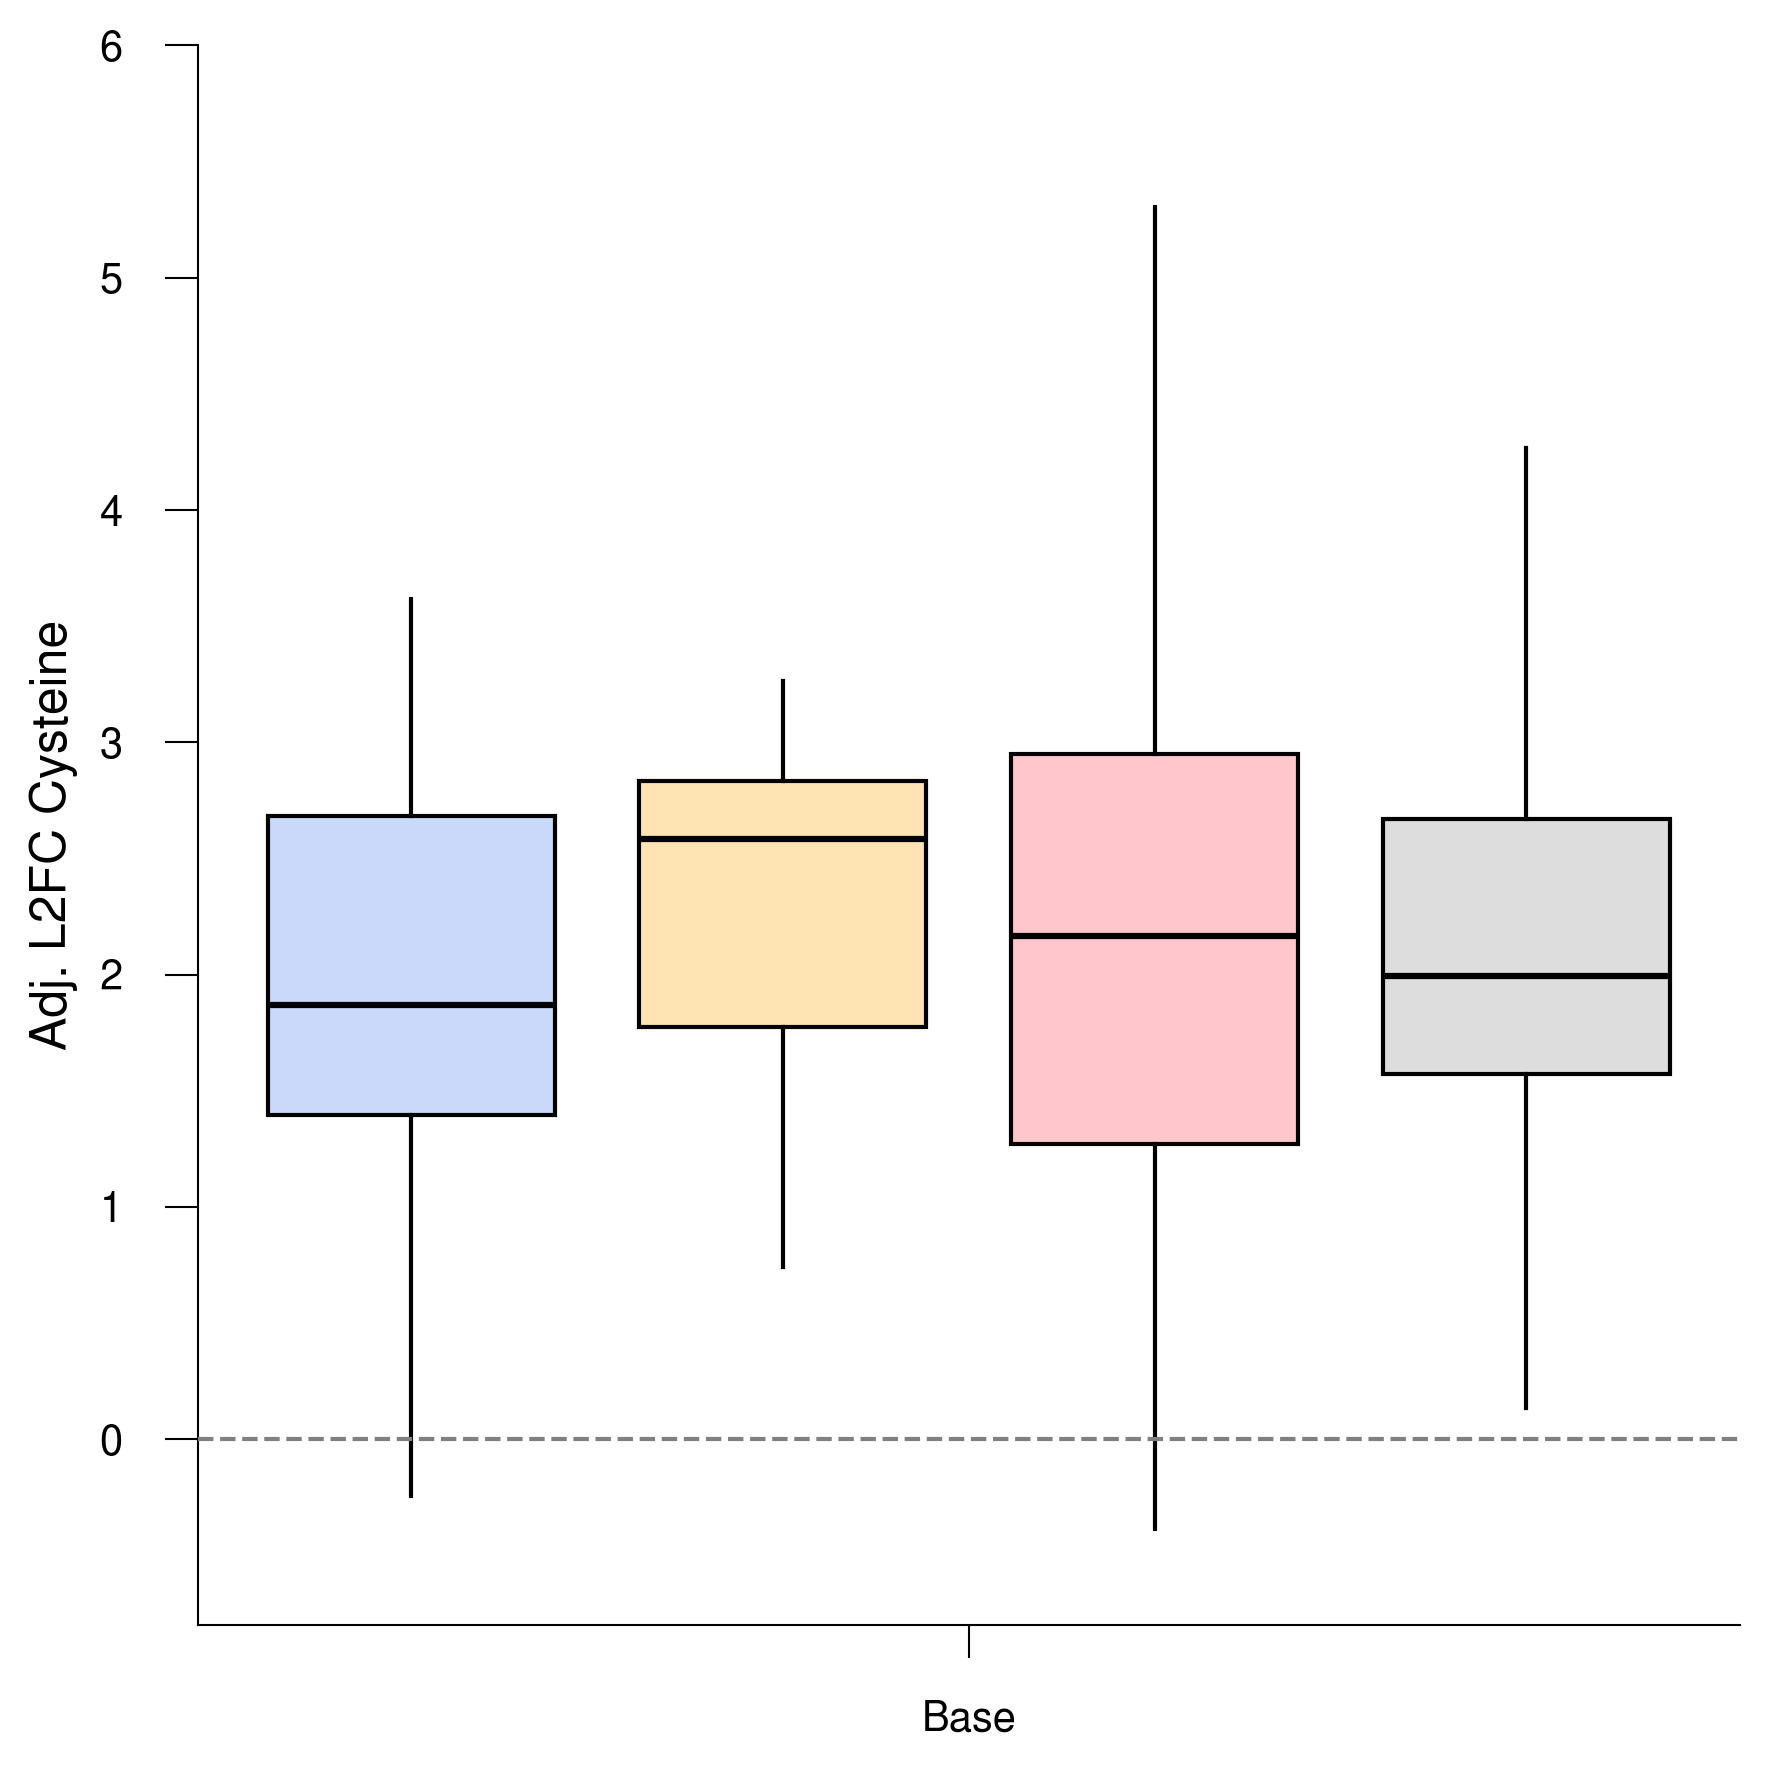

In [ ]:
# adjusted cysteine enrichment boxplot
boxplot_groups={
    "Base": [(per_dataset_dict_adjusted_cys_enrich_l2fc["holec_main"], "cys_l2fc_ext_vs_ms_holec_main"), (per_dataset_dict_adjusted_cys_enrich_l2fc["episcan"], "cys_l2fc_ext_vs_ms_episcan"), (per_dataset_dict_adjusted_cys_enrich_l2fc["ba"], "cys_l2fc_ext_vs_ms_ba"), (per_dataset_dict_adjusted_cys_enrich_l2fc["escape"], "cys_l2fc_ext_vs_ms_escape")],
}

colors={
    "cys_l2fc_ext_vs_ms_holec_main": "#cad8f9",
    "cys_l2fc_ext_vs_ms_episcan": "#ffe4b3",
    "cys_l2fc_ext_vs_ms_ba": "#ffc7cc",
    "cys_l2fc_ext_vs_ms_escape": "#dddddd",
}

plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'Adj. L2FC Cysteine',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (6, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10

}

_=plot_grouped_boxplots(
    boxplot_groups,
    colors=colors,
    legend=None,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.3,
    group_spacing=1.0,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=0,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=0,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style='--',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode='integrated',
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    ylim=(-0.8, 6),
    compute_pvalues=False,
    pvalue_test='wilcoxon',
    cluster_col='louvain_id',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig2_b_per_dataset_adjusted_cysteine_enrichment_relative_to_ms_boxplots", 
)



In [ ]:
%%time
# hydrophobicity shift in binders
dict_of_dfs_pos={
    "ms": ms_dataset_pos,
    "holec_main": holec_dataset.query("label == 1"),
    "episcan": episcan_dataset.query("label == 1"),
    "ba": nmp_ba_data_hla.query("label == 1"),
    "escape": escape_seq_dataset.query("label == 1"),
}

# add peptide col
for df_name, df in tqdm(dict_of_dfs_pos.items()):
    df["peptide"]=df.seq.str.replace("$", "")
    dict_of_dfs_pos[df_name]=df

per_dataset_dict_pos_hydro_shift, summary_df_pos_hydro_shift=compute_delta_gravy_vs_ms(
    dict_of_dfs_pos,
    ms_key="ms",
    peptide_col="peptide",
    allele_col="allele",
    deduplicate=True,
)

100%|██████████| 5/5 [00:00<00:00, 11.74it/s]


CPU times: user 6.65 s, sys: 409 ms, total: 7.05 s
Wall time: 7.04 s


In [ ]:
# rename the cols in each df and then print the matched allele counts for the n values in the figure annotations/caption
for df_name, df in per_dataset_dict_pos_hydro_shift.items():
    print(df_name, len(df))
    df.rename(columns={"delta_gravy_ext_vs_ms": f"delta_gravy_ext_vs_ms_{df_name}"}, inplace=True)
    per_dataset_dict_pos_hydro_shift[df_name]=df

holec_main 16
episcan 12
ba 83
escape 45


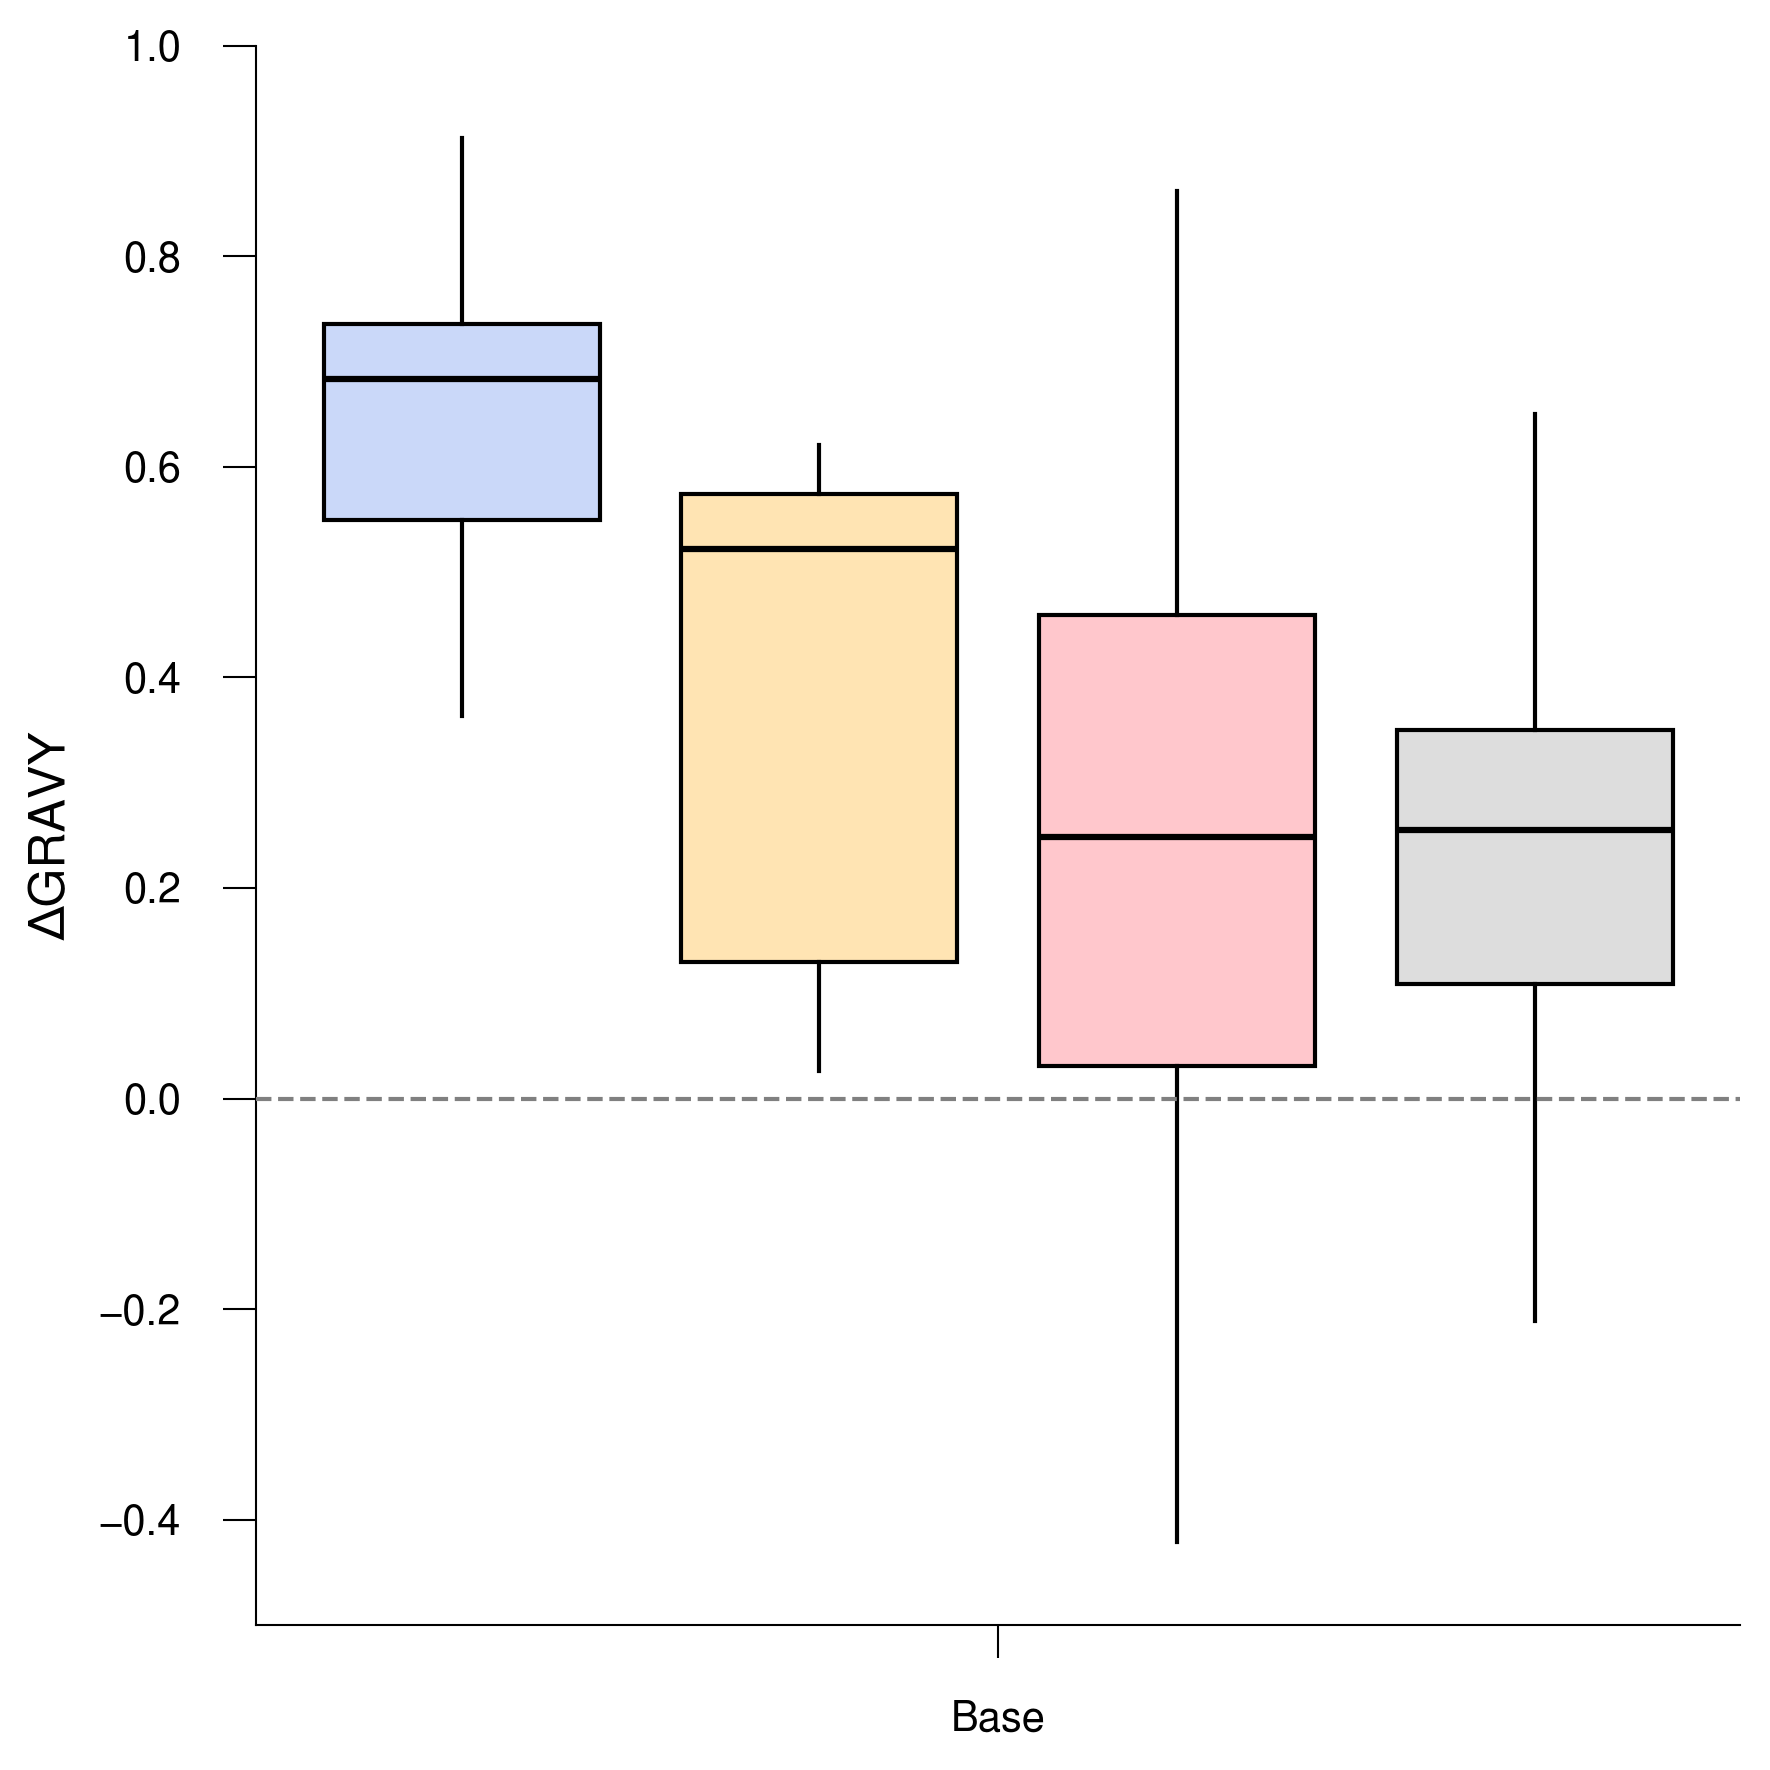

In [ ]:
# hydrophobicity shift boxplots
boxplot_groups={
    "Base": [(per_dataset_dict_pos_hydro_shift["holec_main"], "delta_gravy_ext_vs_ms_holec_main"), (per_dataset_dict_pos_hydro_shift["episcan"], "delta_gravy_ext_vs_ms_episcan"), (per_dataset_dict_pos_hydro_shift["ba"], "delta_gravy_ext_vs_ms_ba"), (per_dataset_dict_pos_hydro_shift["escape"], "delta_gravy_ext_vs_ms_escape")],
}

colors={
    "delta_gravy_ext_vs_ms_holec_main": "#cad8f9",
    "delta_gravy_ext_vs_ms_episcan": "#ffe4b3",
    "delta_gravy_ext_vs_ms_ba": "#ffc7cc",
    "delta_gravy_ext_vs_ms_escape": "#dddddd",
}

plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'ΔGRAVY',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (6, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10
}

_=plot_grouped_boxplots(
    boxplot_groups,
    colors=colors,
    legend=None,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.3,
    group_spacing=1.0,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=0,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=0,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style='--',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode='integrated',
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    ylim=(-0.5, 1.0),
    compute_pvalues=False,
    pvalue_test='wilcoxon',
    cluster_col='louvain_id',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig2_b_per_dataset_delta_gravy_hydrophobicity_relative_to_ms_boxplots", 
)


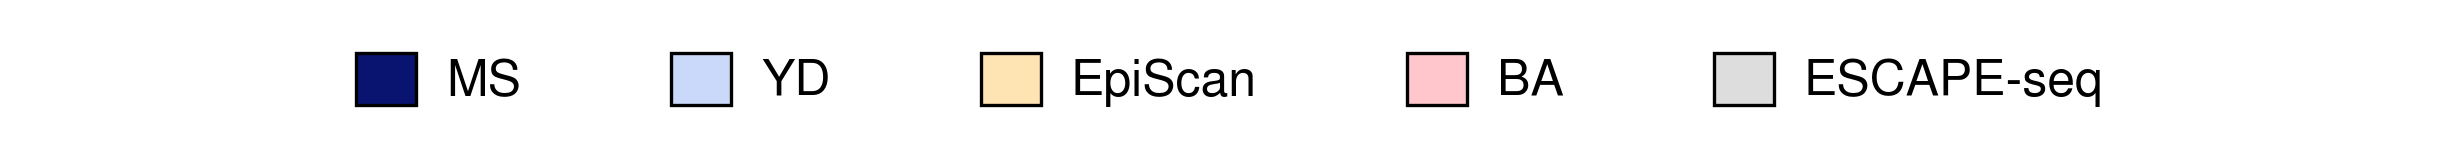

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        "MS": "#081470",
        "YD": "#cad8f9",
        "EpiScan": "#ffe4b3",
        "BA": "#ffc7cc",
        "ESCAPE-seq": "#dddddd",
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig2_b_bottom_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    paired_pvals_resamp.to_csv(f"{associated_data_dir}/jsd_distribution_pvals.csv")
    js_len_df_resamp.to_csv(f"{associated_data_dir}/jsd_distribution_data.csv")
    pos_mapping_pct_df.to_csv(f"{associated_data_dir}/chp_binder_pct_mapping.csv")
    adjusted_cys_enrich_l2fc_df.to_csv(f"{associated_data_dir}/adjusted_cys_enrich_l2fc_df.csv")
    save_dict_pickle(per_dataset_dict_adjusted_cys_enrich_l2fc, f"{associated_data_dir}/per_dataset_dict_adjusted_cys_enrich_l2fc.pkl")
    summary_df_adjusted_cys_enrich_l2fc.to_csv(f"{associated_data_dir}/summary_df_adjusted_cys_enrich_l2fc.csv")
    save_dict_pickle(per_dataset_dict_pos_hydro_shift, f"{associated_data_dir}/per_dataset_dict_pos_hydro_shift.pkl")
    summary_df_pos_hydro_shift.to_csv(f"{associated_data_dir}/summary_df_pos_hydro_shift.csv")

### Fig. 2d: MS benchmarking

In [ ]:
# get same ms set with external model scores
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data_with_benchmarking_model_scores=pd.read_csv(f"{datasets_dir}/ms_test_data_with_benchmarking_model_scores.csv", index_col=0)

In [ ]:
# get ms ap per allele (exclude C0301 as it is not a valid allele for some models)
score_cols=["mhcprime", "mhc_pred_0", "ms_log_odds", "score", "presentation_score", "EL_score", "BA_score", "munis", "transphla", "bigmhc", "deepattentionpan", "Pathogen_score_nmp42", "Neo_score_nmp42", "capsnetmhc_anthem", "capsnetmhc_iedb"]

ms_allele_ap_matrix=compute_ap_matrix_optimized(ms_test_data_with_benchmarking_model_scores.query("allele != 'C0301'"), score_cols, label_col='label', allele_col='allele', disable_tqdm=True)

display(ms_allele_ap_matrix.mean())
print(end="\n")
display(ms_allele_ap_matrix.median())

mhcprime                0.801647
mhc_pred_0              0.790566
ms_log_odds             0.726185
score                   0.690923
presentation_score      0.641678
EL_score                0.594527
BA_score                0.503436
munis                   0.709189
transphla               0.328965
bigmhc                  0.666865
deepattentionpan        0.216149
Pathogen_score_nmp42    0.327341
Neo_score_nmp42         0.587155
capsnetmhc_anthem       0.574912
capsnetmhc_iedb         0.217337
dtype: float64

mhcprime                0.813651
mhc_pred_0              0.812175
ms_log_odds             0.753035
score                   0.712963
presentation_score      0.665156
EL_score                0.607937
BA_score                0.494030
munis                   0.731172
transphla               0.301475
bigmhc                  0.726808
deepattentionpan        0.192828
Pathogen_score_nmp42    0.336819
Neo_score_nmp42         0.606340
capsnetmhc_anthem       0.620963
capsnetmhc_iedb         0.193496
dtype: float64

In [ ]:
# p-values
ms_allele_ap_matrix_pval_df=compute_pairwise_pvalues_general(ms_allele_ap_matrix[score_cols])
display(ms_allele_ap_matrix_pval_df)
display(pval_to_stars(ms_allele_ap_matrix_pval_df))

,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,1.000000e+00,6.828879e-01,4.465440e-19,2.161653e-21,1.039455e-24,1.524609e-24,8.578434e-25,2.377104e-23,6.927405e-25,2.162684e-16,6.927405e-25,6.927405e-25,8.219683e-25,3.785871e-24,6.927405e-25
mhc_pred_0,6.828879e-01,1.000000e+00,1.015511e-13,3.490134e-18,3.181737e-22,2.099401e-23,1.492561e-24,4.236585e-17,6.927405e-25,8.778096e-15,6.927405e-25,7.077217e-25,1.416515e-23,9.525132e-24,6.927405e-25
ms_log_odds,4.465440e-19,1.015511e-13,1.000000e+00,5.425067e-09,1.536904e-19,2.280931e-24,8.045924e-25,4.149881e-02,6.927405e-25,1.664049e-02,6.927405e-25,6.927405e-25,9.960605e-25,1.475275e-23,6.927405e-25
score,2.161653e-21,3.490134e-18,5.425067e-09,1.000000e+00,4.914424e-09,5.245076e-16,7.838099e-23,4.408760e-03,7.077217e-25,6.047354e-01,6.927405e-25,7.230239e-25,1.143899e-17,3.082344e-15,6.927405e-25
presentation_score,1.039455e-24,3.181737e-22,1.536904e-19,4.914424e-09,1.000000e+00,5.100183e-09,6.051061e-22,7.100032e-13,7.709249e-25,5.728186e-04,7.077217e-25,1.156310e-24,1.817205e-12,3.499005e-11,6.927405e-25
EL_score,1.524609e-24,2.099401e-23,2.280931e-24,5.245076e-16,5.100183e-09,1.000000e+00,2.143345e-23,5.850337e-20,7.386538e-25,8.899199e-08,6.927405e-25,1.014059e-23,1.720918e-02,1.707990e-01,6.927405e-25
BA_score,8.578434e-25,1.492561e-24,8.045924e-25,7.838099e-23,6.051061e-22,2.143345e-23,1.000000e+00,2.922967e-23,2.426800e-23,1.790495e-16,9.343120e-25,2.160822e-20,5.366455e-22,4.563656e-14,6.927405e-25
munis,2.377104e-23,4.236585e-17,4.149881e-02,4.408760e-03,7.100032e-13,5.850337e-20,2.922967e-23,1.000000e+00,7.386538e-25,1.142069e-01,6.927405e-25,4.032726e-24,2.685726e-21,2.245675e-20,6.927405e-25
transphla,6.927405e-25,6.927405e-25,6.927405e-25,7.077217e-25,7.709249e-25,7.386538e-25,2.426800e-23,7.386538e-25,1.000000e+00,9.328316e-24,1.551014e-06,6.663490e-01,6.927405e-25,1.017529e-24,1.428313e-06
bigmhc,2.162684e-16,8.778096e-15,1.664049e-02,6.047354e-01,5.728186e-04,8.899199e-08,1.790495e-16,1.142069e-01,9.328316e-24,1.000000e+00,6.401357e-24,4.570517e-22,3.833885e-09,1.258741e-08,8.946688e-24


,mhcprime,mhc_pred_0,ms_log_odds,score,presentation_score,EL_score,BA_score,munis,transphla,bigmhc,deepattentionpan,Pathogen_score_nmp42,Neo_score_nmp42,capsnetmhc_anthem,capsnetmhc_iedb
mhcprime,ns,ns,****,****,****,****,****,****,****,****,****,****,****,****,****
mhc_pred_0,ns,ns,****,****,****,****,****,****,****,****,****,****,****,****,****
ms_log_odds,****,****,ns,****,****,****,****,*,****,*,****,****,****,****,****
score,****,****,****,ns,****,****,****,**,****,ns,****,****,****,****,****
presentation_score,****,****,****,****,ns,****,****,****,****,***,****,****,****,****,****
EL_score,****,****,****,****,****,ns,****,****,****,****,****,****,*,ns,****
BA_score,****,****,****,****,****,****,ns,****,****,****,****,****,****,****,****
munis,****,****,*,**,****,****,****,ns,****,ns,****,****,****,****,****
transphla,****,****,****,****,****,****,****,****,ns,****,****,ns,****,****,****
bigmhc,****,****,*,ns,***,****,****,ns,****,ns,****,****,****,****,****


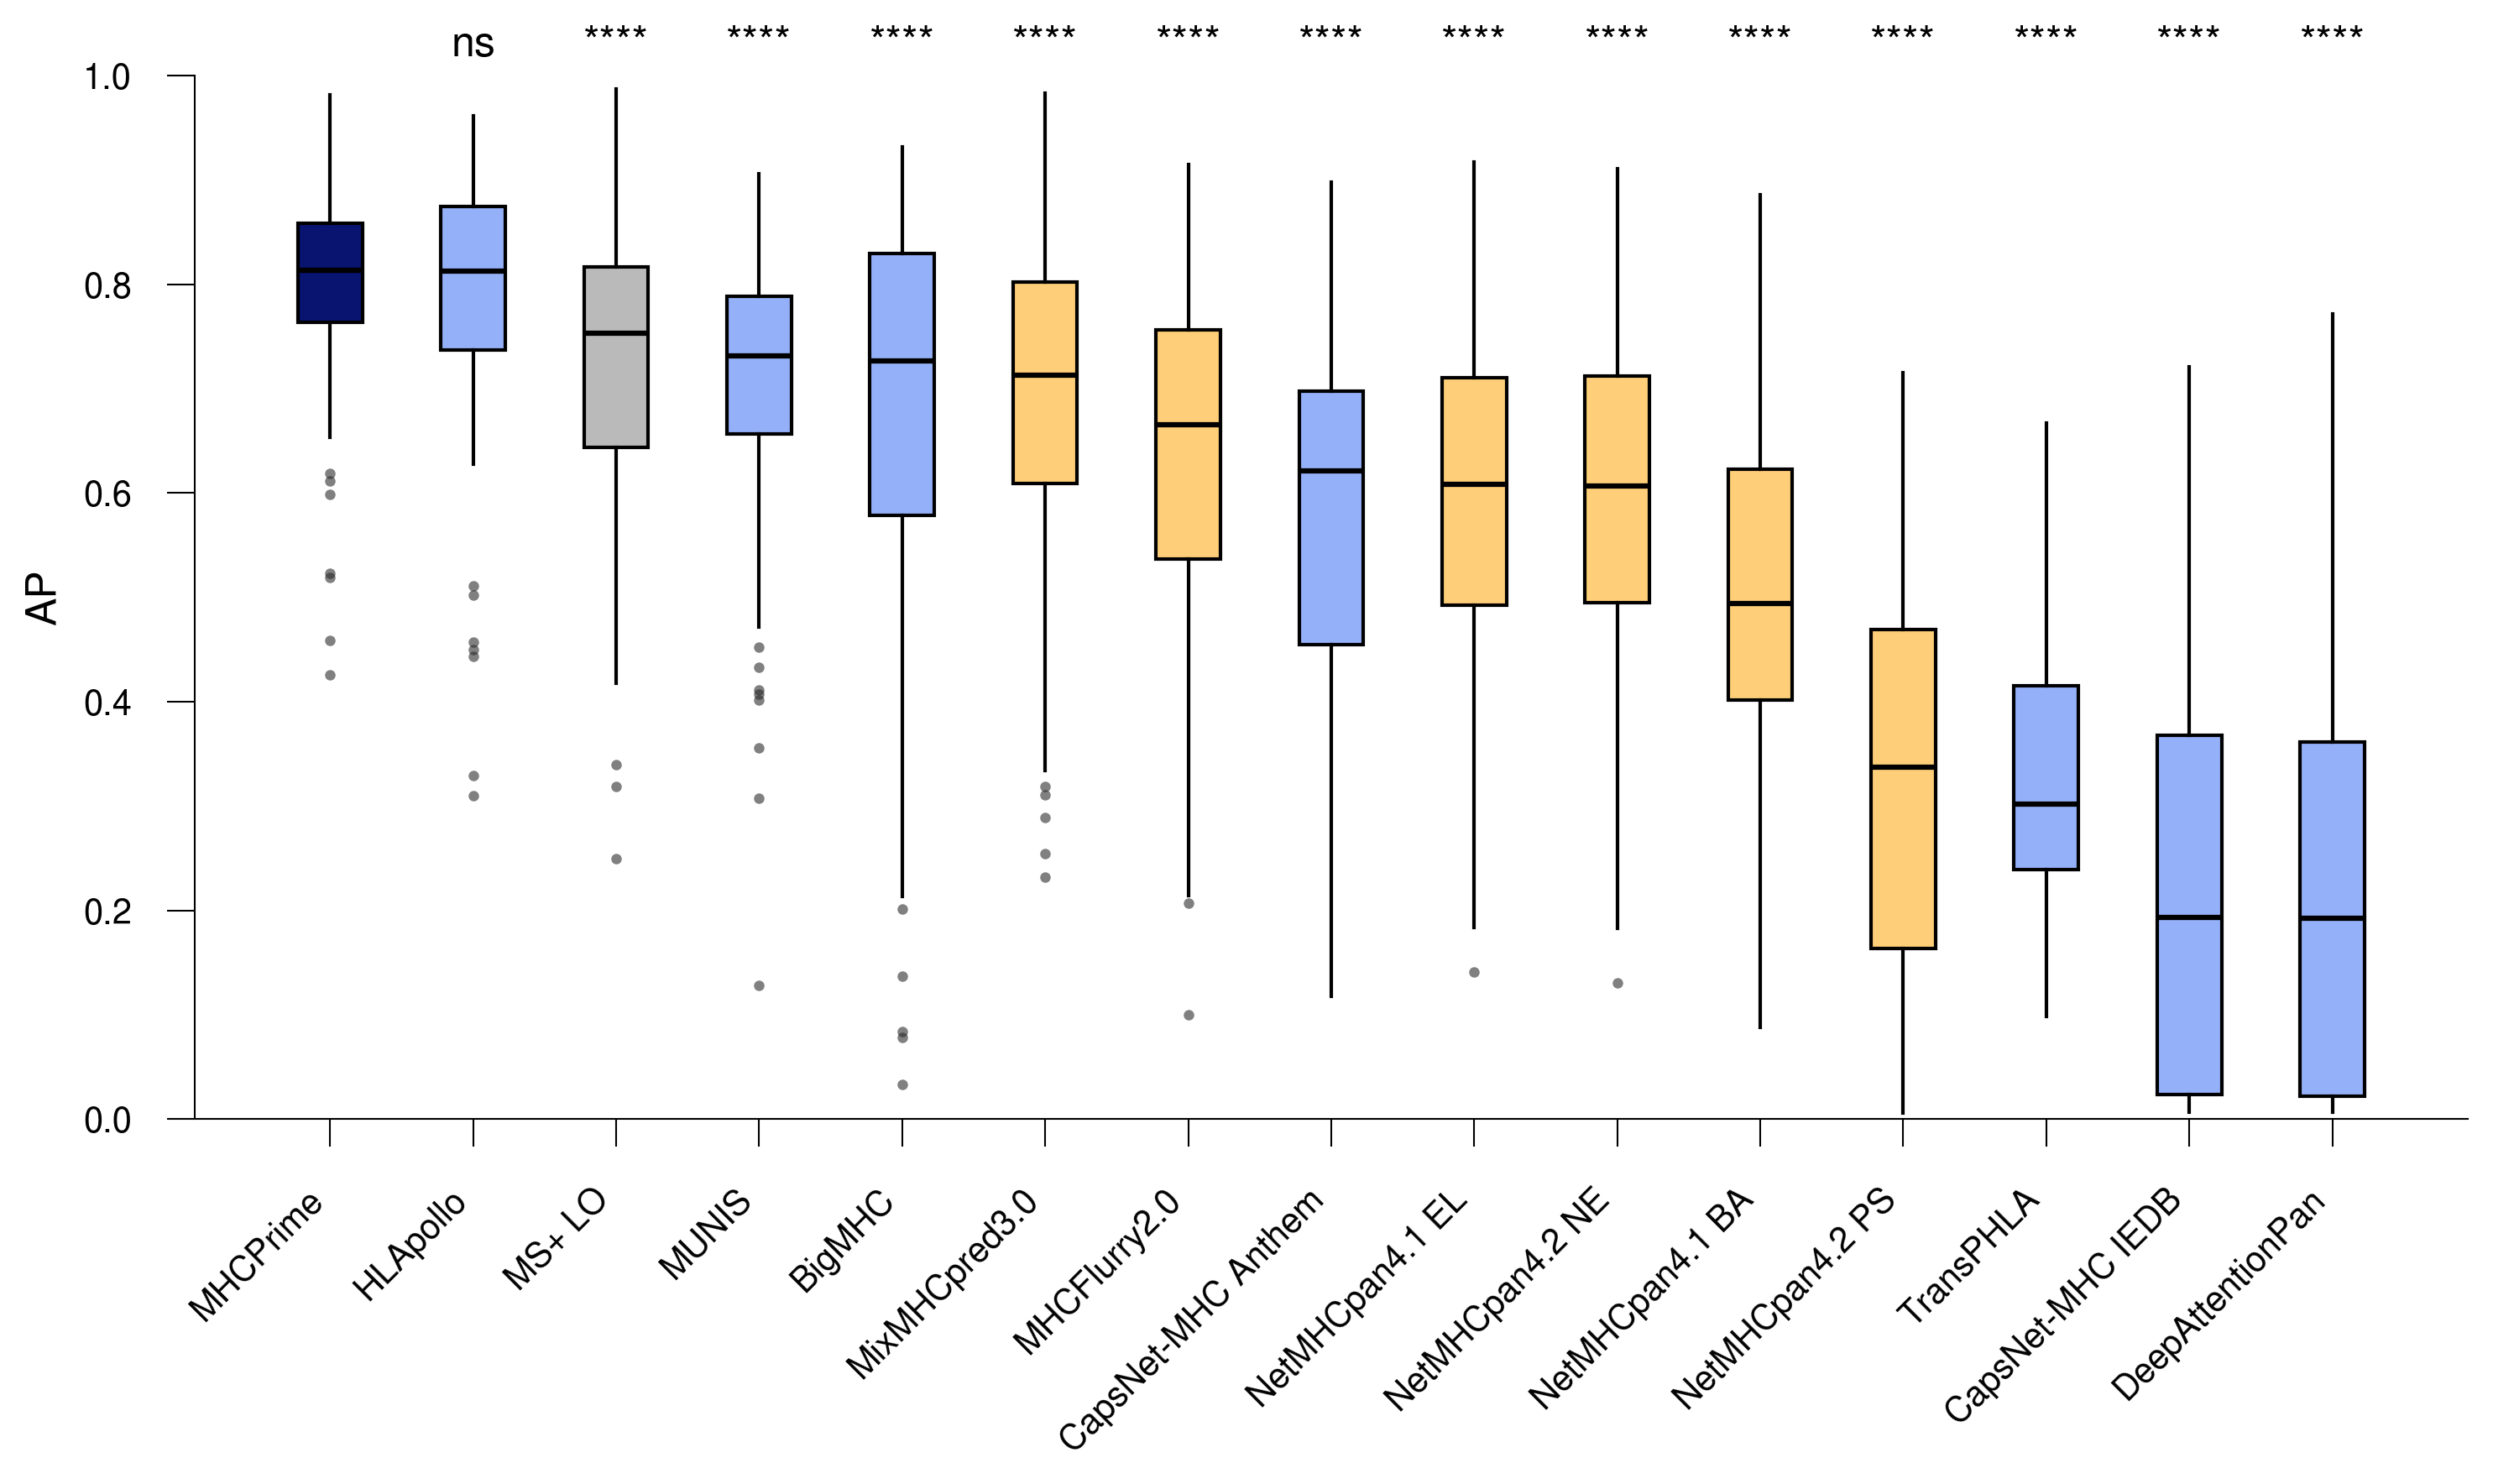

In [ ]:
# ms performance boxplots
boxplot_groups={
    "MHCPrime": [(ms_allele_ap_matrix, 'mhcprime')],
    "HLApollo": [(ms_allele_ap_matrix, 'mhc_pred_0')],
    "MS+ LO": [(ms_allele_ap_matrix, 'ms_log_odds')],
    "MixMHCpred3.0": [(ms_allele_ap_matrix, 'score')],
    "MUNIS": [(ms_allele_ap_matrix, 'munis')],
    "BigMHC": [(ms_allele_ap_matrix, 'bigmhc')],
    "MHCFlurry2.0": [(ms_allele_ap_matrix, 'presentation_score')],
    "NetMHCpan4.1 EL": [(ms_allele_ap_matrix, 'EL_score')],
    "NetMHCpan4.2 NE": [(ms_allele_ap_matrix, 'Neo_score_nmp42')],
    "CapsNet-MHC Anthem": [(ms_allele_ap_matrix, 'capsnetmhc_anthem')],
    "NetMHCpan4.1 BA": [(ms_allele_ap_matrix, 'BA_score')],
    "DeepAttentionPan": [(ms_allele_ap_matrix, 'deepattentionpan')],
    "CapsNet-MHC IEDB": [(ms_allele_ap_matrix, 'capsnetmhc_iedb')],
    "TransPHLA": [(ms_allele_ap_matrix, 'transphla')],
    "NetMHCpan4.2 PS": [(ms_allele_ap_matrix, 'Pathogen_score_nmp42')],
     
}

transformer_based_color="#94B0F8"
nn_based_color="#ffce78"
lo_color="#bababa"
colors={
    "mhcprime": "#081470",
    "mhc_pred_0": transformer_based_color,
    "ms_log_odds": lo_color,
    "presentation_score":nn_based_color, 
    "score":nn_based_color, 
    "EL_score": nn_based_color,
    "BA_score": nn_based_color,
    "munis": transformer_based_color, 
    "transphla": transformer_based_color,
    "bigmhc": transformer_based_color, 
    "deepattentionpan": transformer_based_color,
    "Pathogen_score_nmp42":nn_based_color, 
    "Neo_score_nmp42":nn_based_color, 
    "capsnetmhc_anthem": transformer_based_color,
    "capsnetmhc_iedb": transformer_based_color, 
}

plot_params = {
    'title': '',
    'title_fontsize': 16,
    'title_bold': False,
    'xlabel': '',
    'ylabel': 'AP',
    'xlabel_fontsize': 12,
    'ylabel_fontsize': 12,
    'figsize': (10, 6),
    'dpi': 300,
    'legend_fontsize': 12,
    'legend_cols': 5,
    'legend_handle_size': 0.9,
    'marker_size': 3,
    'axis_linewidth': 0.5,
    'tick_length': 8.0,
    'xlabel_pad': 5.0,
    'ylabel_pad': 5.0,
    'xtick_labelsize': 10,
    'ytick_labelsize': 10,
    'xtick_rotation': 45

}

_=plot_grouped_boxplots(
    boxplot_groups,
    colors=colors,
    legend=None,
    plot_params=plot_params,
    grid_alpha=0.0,
    default_font='Nimbus Sans',
    box_width=0.1,
    group_spacing=0.1,
    box_spacing=0.05,
    box_outline_color='black',
    box_outline_width=1.0,
    box_flier_marker='o',
    box_flier_size=3,
    box_flier_color="#2B2B2B",
    box_flier_alpha=0.6,
    box_flier_edge_width=0,
    box_median_color='black',
    box_median_width=1.5,
    box_whisker_style='-',
    box_whisker_width=1.0,
    box_notch=False,
    box_patch_alpha=1.0,
    hline_y=None,
    hline_label=None,
    hline_color='gray',
    hline_width=1.0,
    hline_style='--',
    hline_text=None,
    hline_text_position='above',
    hline_text_color=None,
    hline_text_fontsize=10,
    hline_text_offset=0.01,
    hline_text_x_offset=0.05,
    hline_in_legend=True,
    reference_hlines=None,
    legend_mode=None,
    legend_loc='lower center',
    legend_bbox=None,
    legend_ncol=None,
    ylim=(0, 1.0),
    compute_pvalues=False,
    pvalue_test='wilcoxon', 
    cluster_col='louvain_id',
    sort_by ="median",
    sort_ascending=False, 
    pval_df=ms_allele_ap_matrix_pval_df,
    pval_ref_col="mhcprime",
    pval_ref_stars_only=True,
    pval_format='stars',
    pval_fontsize=12,
    pval_color='black',
    pval_star_y=None,
    pval_star_y_frac=1.01,
    pval_star_text_offset=0.0,

    save_path=None,
    # save_path=f"{central_figure_dir}/fig2_d_ms_baseline_allele_ap_performance_boxplots_per_model", 
)

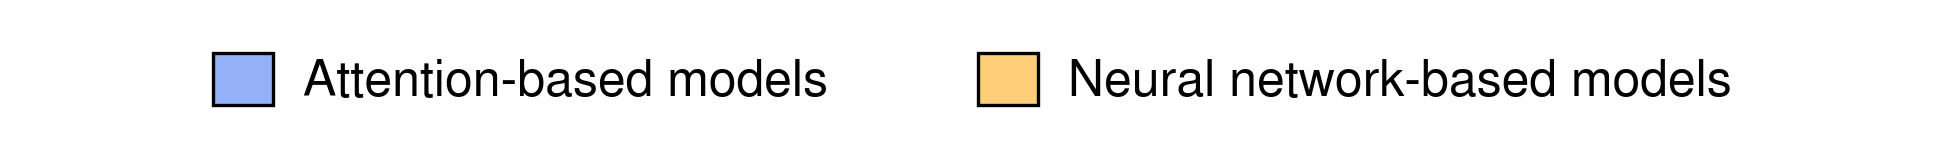

In [ ]:
# legend resized and formatted in illustrator
plot_horizontal_legend(
    legend_dict={
        'Attention-based models': '#94B0F8',
        'Neural network-based models': '#ffce78',
    },
    swatch_size=12,
    text_size=12,
    item_spacing=30,
    swatch_text_gap=6,
    swatch_outline_color='black',
    swatch_outline_width=0.8,
    figsize=None,
    dpi=300,
    default_font='Nimbus Sans',
    save_path=None,
    # save_path=f"{central_figure_dir}/fig2_d_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    ms_allele_ap_matrix.to_csv(f"{associated_data_dir}/ms_benchmarking_allele_ap_matrix.csv")
    ms_allele_ap_matrix_pval_df.to_csv(f"{associated_data_dir}/ms_benchmarking_allele_ap_matrix_pval_df.csv")

### Fig. 2e: Non-MS benchmarking

In [ ]:
%%time
# get the major collected dfs

# get same ms set with external model scores
datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "MS_Train_Test_Sets"
ms_test_data_with_benchmarking_model_scores=pd.read_csv(f"{datasets_dir}/ms_test_data_with_benchmarking_model_scores.csv", index_col=0)

# yd train and test sets
holec_datasets_dir = DATA_DIR / "Training_Datasets" / "Processed" / "Holec_et_al_2025"
holec_test_set_with_benchmarking_model_scores  = pd.read_csv(f"{holec_datasets_dir}/holec_test_set_with_benchmarking_model_scores.csv", index_col=0)

# episcan train and test sets
episcan_train_test_dir = DATA_DIR / "Training_Datasets" / "Processed" / "EpiScan"
episcan_r9_test_set_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/episcan_r9_test_set_with_benchmarking_model_scores.csv", index_col=0)
episcan_rt_test_set_with_benchmarking_model_scores=pd.read_csv(f"{episcan_train_test_dir}/episcan_rt_test_set_with_benchmarking_model_scores.csv", index_col=0)

# ba test sets
nmp_ba_data_hla_data_with_benchmarking_model_scores=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/BA/nmp_ba_data_hla_data_with_benchmarking_model_scores.csv", index_col=0)
ba_full_cls_test_set=pd.read_csv(f"{DATA_DIR}/Training_Datasets/Processed/BA/ba_full_cls_test_set.csv", index_col=0)

# escape seq test set
escape_seq_datasets_dir = DATA_DIR / "Training_Datasets/Processed/ESCAPE_seq"
escape_seq_full_cls_test_set_with_benchmarking_model_scores=pd.read_csv(f"{escape_seq_datasets_dir}/escape_seq_full_cls_test_set_with_benchmarking_model_scores.csv", index_col=0)

CPU times: user 9.16 s, sys: 728 ms, total: 9.89 s
Wall time: 9.88 s


In [ ]:
%%time
# process all
ms_test_data_with_benchmarking_model_scores=full_process_data(ms_test_data_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ms_test_data_with_benchmarking_model_scores=create_seq_allele_column(ms_test_data_with_benchmarking_model_scores)

holec_test_set_with_benchmarking_model_scores=full_process_data(holec_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
holec_test_set_with_benchmarking_model_scores=create_seq_allele_column(holec_test_set_with_benchmarking_model_scores)

episcan_r9_test_set_with_benchmarking_model_scores=full_process_data(episcan_r9_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_r9_test_set_with_benchmarking_model_scores=create_seq_allele_column(episcan_r9_test_set_with_benchmarking_model_scores)

episcan_rt_test_set_with_benchmarking_model_scores=full_process_data(episcan_rt_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
episcan_rt_test_set_with_benchmarking_model_scores=create_seq_allele_column(episcan_rt_test_set_with_benchmarking_model_scores)

ba_full_cls_test_set=full_process_data(ba_full_cls_test_set, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
ba_full_cls_test_set=create_seq_allele_column(ba_full_cls_test_set)

nmp_ba_data_hla_data_with_benchmarking_model_scores=full_process_data(nmp_ba_data_hla_data_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
nmp_ba_data_hla_data_with_benchmarking_model_scores=create_seq_allele_column(nmp_ba_data_hla_data_with_benchmarking_model_scores)

escape_seq_full_cls_test_set_with_benchmarking_model_scores=full_process_data(escape_seq_full_cls_test_set_with_benchmarking_model_scores, mhc_seq_dict, remove_flank=True, add_pseudo_label=False)
escape_seq_full_cls_test_set_with_benchmarking_model_scores=create_seq_allele_column(escape_seq_full_cls_test_set_with_benchmarking_model_scores)

CPU times: user 3.5 s, sys: 374 ms, total: 3.87 s
Wall time: 3.87 s


In [ ]:
# isolate ba set
ba_full_cls_test_set_with_benchmarking_model_scores=nmp_ba_data_hla_data_with_benchmarking_model_scores[nmp_ba_data_hla_data_with_benchmarking_model_scores.seq_allele.isin(ba_full_cls_test_set.seq_allele.tolist())].copy()
print_data_stats(ba_full_cls_test_set_with_benchmarking_model_scores)

Total: 111,500
Pos: 1,115 | 1.00%
Neg: 110,385 | 99.00%
N alleles: 71


In [ ]:
# add seq len
ms_test_data_with_benchmarking_model_scores["seq_len"]=ms_test_data_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)
holec_test_set_with_benchmarking_model_scores["seq_len"]=holec_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)
episcan_r9_test_set_with_benchmarking_model_scores["seq_len"]=episcan_r9_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)
episcan_rt_test_set_with_benchmarking_model_scores["seq_len"]=episcan_rt_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)
ba_full_cls_test_set_with_benchmarking_model_scores["seq_len"]=ba_full_cls_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)
escape_seq_full_cls_test_set_with_benchmarking_model_scores["seq_len"]=escape_seq_full_cls_test_set_with_benchmarking_model_scores.seq.str.replace("$", "").apply(len)

In [ ]:
def report_nans(df, cols):
    for col in cols:
        if col not in df.columns:
            print(f"{col}: column not found")
        else:
            n_nan = df[col].isna().sum()
            if n_nan > 0:
                print(f"{col}: {n_nan} NaNs")
            else:
                print(f"{col}: no NaNs")

score_cols=["mhcprime", "mhc_pred_0", "ms_log_odds", "score", "presentation_score", "EL_score", "BA_score", "munis", "transphla", "bigmhc", "deepattentionpan", "EL_score_nmp42", "Pathogen_score_nmp42", "Neo_score_nmp42", "capsnetmhc_anthem", "capsnetmhc_iedb"]

print("MS") # nans for C0301
report_nans(ms_test_data_with_benchmarking_model_scores, score_cols)
print(end="\n")

print("Holec")
report_nans(holec_test_set_with_benchmarking_model_scores, score_cols)
print(end="\n")

print("R9")
report_nans(episcan_r9_test_set_with_benchmarking_model_scores, score_cols)
print(end="\n")

print("RT")
report_nans(episcan_rt_test_set_with_benchmarking_model_scores, score_cols)
print(end="\n")

print("BA")
report_nans(ba_full_cls_test_set_with_benchmarking_model_scores, score_cols)
print(end="\n")

print("ESCAPE-seq")
report_nans(escape_seq_full_cls_test_set_with_benchmarking_model_scores, score_cols)
print(end="\n")

MS
mhcprime: no NaNs
mhc_pred_0: 500 NaNs
ms_log_odds: no NaNs
score: 500 NaNs
presentation_score: no NaNs
EL_score: no NaNs
BA_score: no NaNs
munis: no NaNs
transphla: no NaNs
bigmhc: no NaNs
deepattentionpan: no NaNs
EL_score_nmp42: no NaNs
Pathogen_score_nmp42: no NaNs
Neo_score_nmp42: no NaNs
capsnetmhc_anthem: no NaNs
capsnetmhc_iedb: no NaNs

Holec
mhcprime: no NaNs
mhc_pred_0: no NaNs
ms_log_odds: no NaNs
score: no NaNs
presentation_score: no NaNs
EL_score: no NaNs
BA_score: no NaNs
munis: no NaNs
transphla: no NaNs
bigmhc: no NaNs
deepattentionpan: no NaNs
EL_score_nmp42: no NaNs
Pathogen_score_nmp42: no NaNs
Neo_score_nmp42: no NaNs
capsnetmhc_anthem: no NaNs
capsnetmhc_iedb: no NaNs

R9
mhcprime: no NaNs
mhc_pred_0: no NaNs
ms_log_odds: no NaNs
score: no NaNs
presentation_score: no NaNs
EL_score: no NaNs
BA_score: no NaNs
munis: no NaNs
transphla: no NaNs
bigmhc: no NaNs
deepattentionpan: no NaNs
EL_score_nmp42: no NaNs
Pathogen_score_nmp42: no NaNs
Neo_score_nmp42: no NaNs
c

In [ ]:
# get colors
color_dict={
    "mhcprime": "#081470",
    "mhc_pred_0": "#657fae",
    "ms_log_odds": "#a4a4a4",
    "presentation_score":"#5F968D", 
    "score":"#1F3C37", 
    "EL_score": "#ffb55c",
    "BA_score": "#ffdea4",
    "munis": "#6D83FF",
    "transphla": "#5A4D98",
    "bigmhc": "#7DCBBB", 
    "deepattentionpan": "#FBE183", 
    "Pathogen_score_nmp42":"#ffc7cc", 
    "Neo_score_nmp42":"#d34a4d", 
    "capsnetmhc_iedb": "#641A1E", 
    "capsnetmhc_anthem": "#DA7C81", 
}

score_cols=['mhcprime', 'mhc_pred_0', 'ms_log_odds', 'munis', 'bigmhc', 'score', 'presentation_score', 'capsnetmhc_anthem', 'EL_score', 'Neo_score_nmp42',  'BA_score', 'Pathogen_score_nmp42', 'transphla', "capsnetmhc_iedb", 'deepattentionpan']

def get_colors_for_score_cols(score_cols, color_dict):
    return [color_dict[col] for col in score_cols if col in color_dict]

colors=get_colors_for_score_cols(score_cols, color_dict)
print(len(colors))

15


Processing datasets: 100%|██████████| 5/5 [00:15<00:00,  3.03s/it]


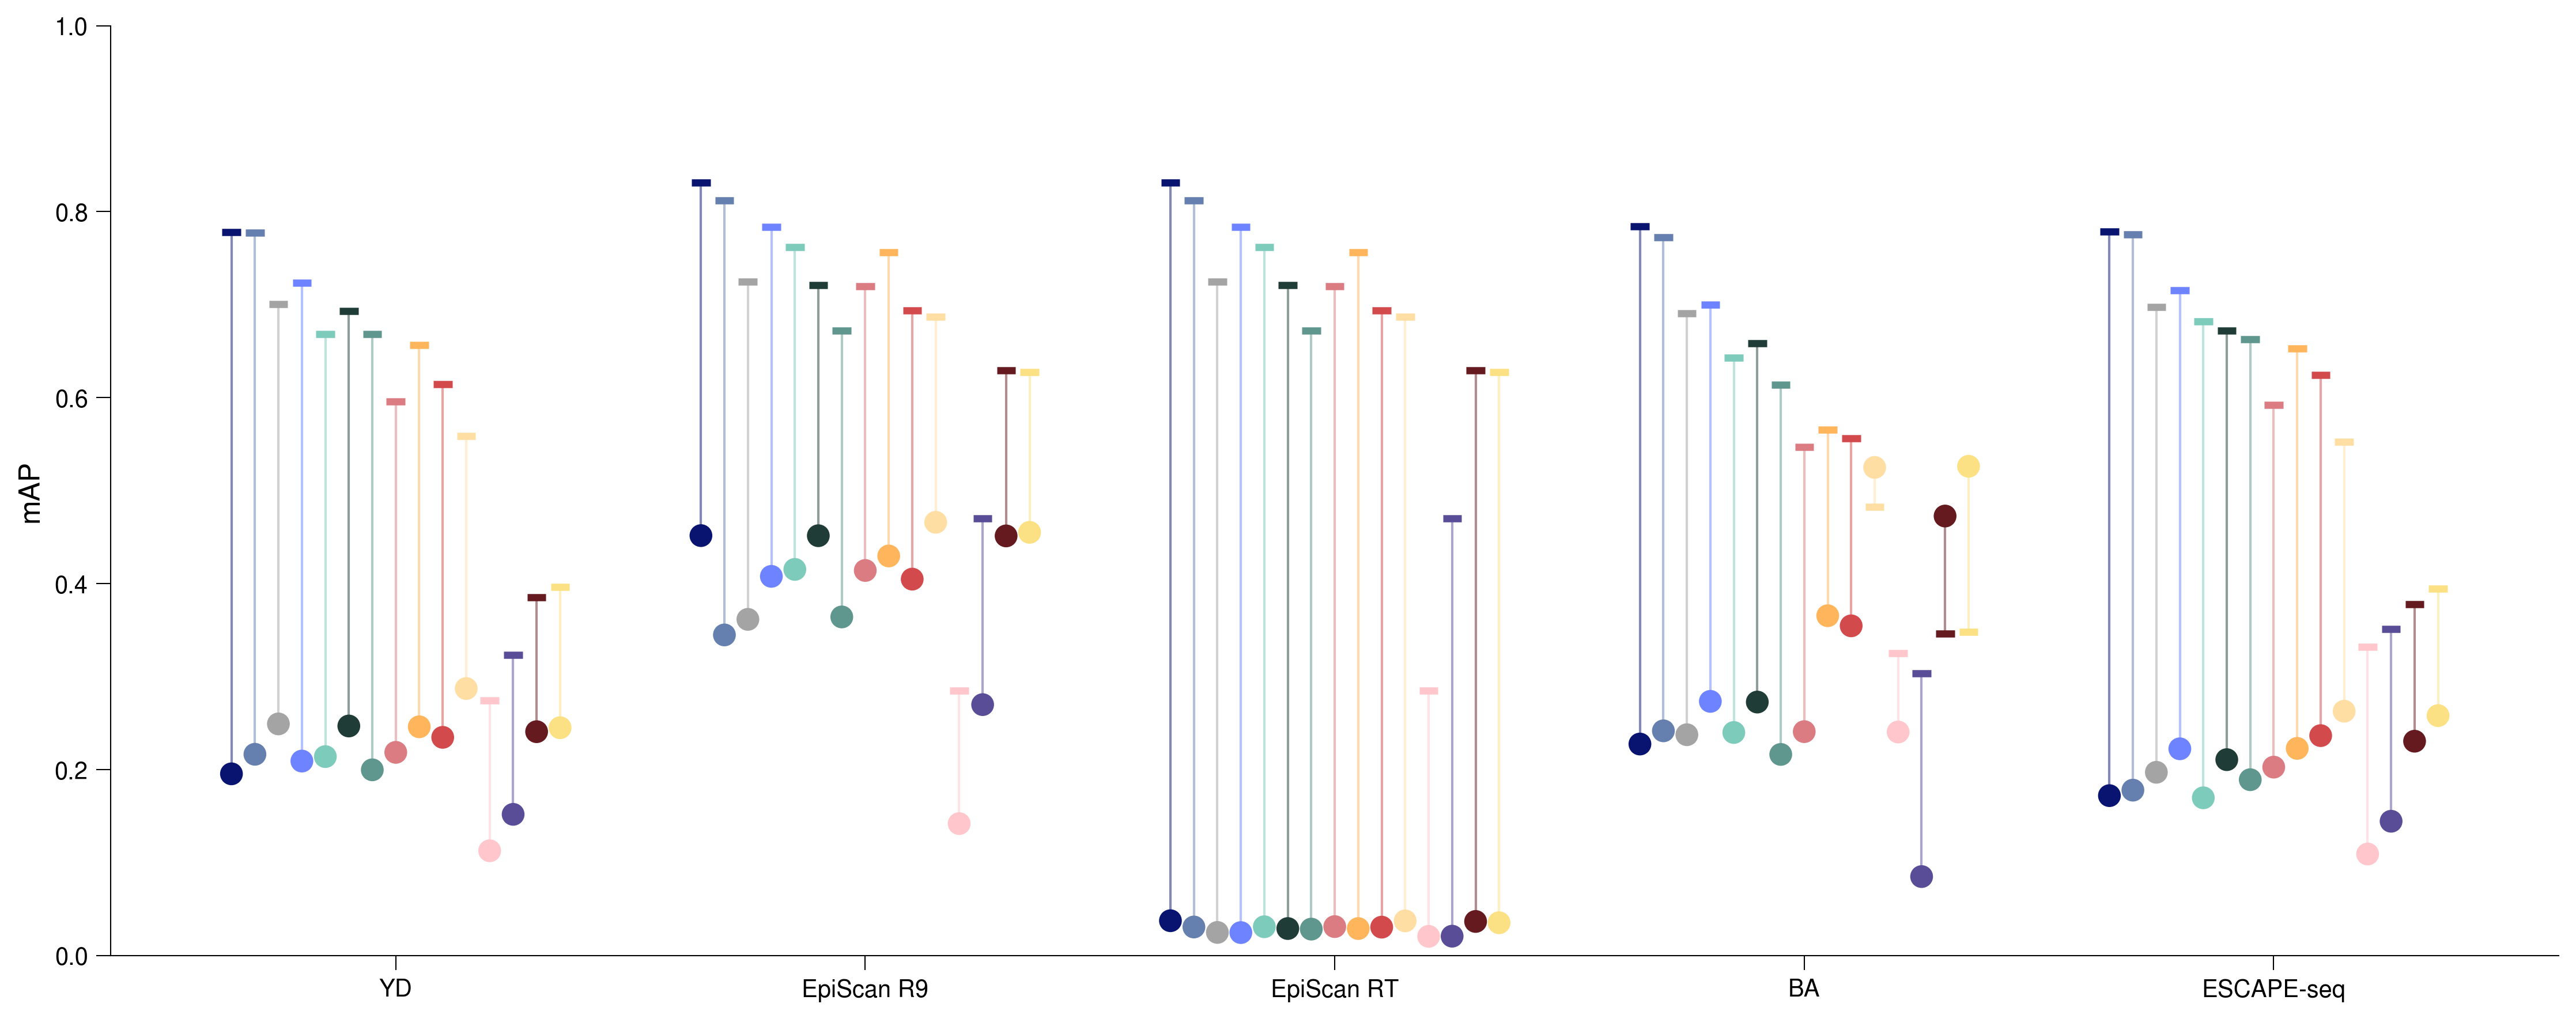

In [ ]:
# plot non-ms and matched ms performance
dataset_to_ap_df={
    "MS": ms_test_data_with_benchmarking_model_scores,
    "YD": holec_test_set_with_benchmarking_model_scores,
    "EpiScan R9": episcan_r9_test_set_with_benchmarking_model_scores,
    "EpiScan RT": episcan_rt_test_set_with_benchmarking_model_scores,
    "BA": ba_full_cls_test_set_with_benchmarking_model_scores,
    "ESCAPE-seq": escape_seq_full_cls_test_set_with_benchmarking_model_scores,
}

# square_aspect=True
square_aspect=False
jitter=0.7
point_size=90
figsize=(15,6)

ax, plot_data_df, summary_df=plot_jitter_ms_vs_external(
    df_dict=dataset_to_ap_df,
    score_cols=score_cols,
    colors=colors,
    ref_key='MS',
    label_col='label',
    allele_col='allele',
    seq_len_col='seq_len',
    figsize=figsize,
    dpi=300,
    default_font='Nimbus Sans',
    jitter=jitter,
    point_size=point_size,
    point_alpha=1.0,
    point_edge_color='none',
    point_edge_width=0,
    point_marker='o',
    show_mean=False,
    mean_above_points=True,
    mean_color='black',
    mean_width=0.8,
    mean_style='--',
    mean_length_pad=0.05,
    title=None,
    title_fontsize=14,
    title_bold=False,
    xlabel=None,
    ylabel="mAP",
    xlabel_fontsize=12,
    ylabel_fontsize=12,
    xlabel_pad=4.0,
    ylabel_pad=4.0,
    xtick_labelsize=10,
    ytick_labelsize=10,
    xtick_rotation=0,
    xtick_ha='center',
    despine=True,
    spine_width=0.5,
    tick_length=6.0,
    tick_width=0.5,
    tick_direction='out',
    ylim=(0, 1),
    grid_alpha=0.0,
    hide_legend=True,
    legend_fontsize=8,
    legend_loc='upper center',
    legend_bbox=(0.5, -0.15),
    legend_ncol=4,
    legend_frameon=False,
    square_aspect=square_aspect,
    show=True,
    ref_marker='T',
    ref_marker_size=point_size,
    ref_line_width=2.0,
    t_cap_width=0.02,
    t_line_width=1.0,
    t_cap_line_width=3.0,
    save_path=None,
    # save_path=f"{central_figure_dir}/fig2_e_external_dataset_versus_ms_jitter_plot_across_models",
)

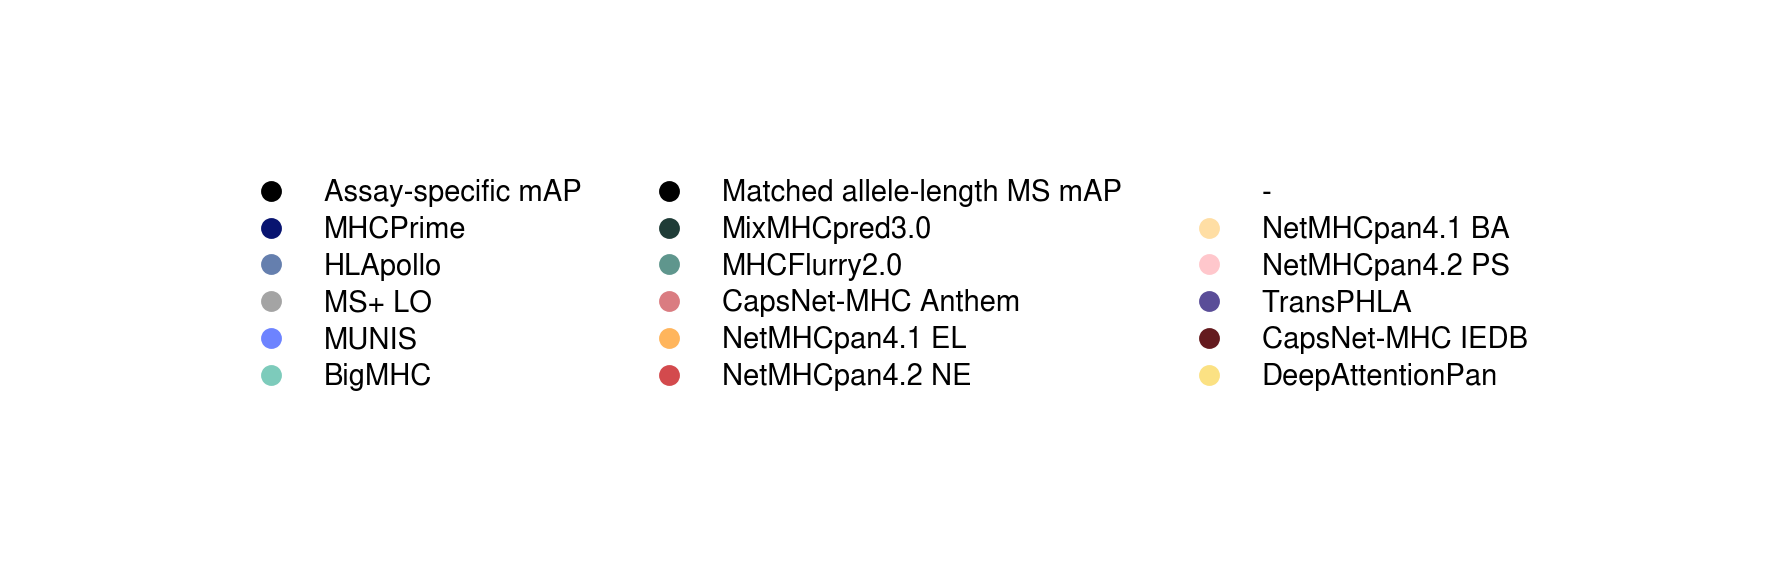

In [ ]:
# plot legend (adjusted in illustrator)
legend_dict={
    "Assay-specific mAP": "#000000", # first var
    'MHCPrime': '#081470',
    'HLApollo': '#657fae',
    'MS+ LO': '#a4a4a4',
    'MUNIS': '#6D83FF',
    'BigMHC': '#7DCBBB',

    "Matched allele-length MS mAP": "#000000", # second for block
    'MixMHCpred3.0': '#1F3C37',
    'MHCFlurry2.0': '#5F968D',
    'CapsNet-MHC Anthem': '#DA7C81',
    'NetMHCpan4.1 EL': '#ffb55c',
    'NetMHCpan4.2 NE': '#d34a4d',

    "-": "#ffffff", # buffer, delete later
    'NetMHCpan4.1 BA': '#ffdea4',
    'NetMHCpan4.2 PS': '#ffc7cc',
    'TransPHLA': '#5A4D98',
    'CapsNet-MHC IEDB': '#641A1E',
    'DeepAttentionPan': '#FBE183'
}

plot_circle_marker_legend(
    legend_dict,
    ncol=3, 
    figsize=(6, 2), # display size
    # figsize=(25, 6), # download size
    dpi=300, 
    # fontsize=8, 
    fontsize=7, 
    marker='o', 
    marker_size=4,
    default_font='Nimbus Sans', 
    row_spacing=0.3,
    save_path=None
    # save_path=f"{central_figure_dir}/fig2_e_legend",
)

In [ ]:
"""
Save dataframes associated with figures.
"""
save_dfs=False
# save_dfs=True

if save_dfs:
    plot_data_df.to_csv(f"{associated_data_dir}/nonms_benchmarking_plot_data_df.csv")
    summary_df.to_csv(f"{associated_data_dir}/nonms_benchmarking_summary_df.csv")